# Step-wise identification of putative sympathaodrenal cell populations in the Daniocell atlas

In [139]:
library(ggrepel)
library(ggplot2)
library(dplyr)
library(Seurat)
library(tidyr) 
library(dplyr)
library(AUCell)
library(RColorBrewer)
library(tibble)
library(stringr)
library(DescTools)

source("../sc_analysis_palettes_and_helpers.r")

# set working directory
setwd("R_out/daniocell/")
dat_name <- "daniocell"

## Load data
Count matrix and metadata tables were retrieved from GEO GSE223922 in 2024.  
Extended cluster metadata was directly retrieved from https://daniocell.nichd.nih.gov/.  
From: Sur et al. 2023: https://doi.org/10.1016/j.devcel.2023.11.001.

In [ ]:
dat_name <- "daniocell"

# load counts
dat.data <- Read10X(data.dir = "daniocell_counts", gene.column = 1,cell.column = 1)


In [ ]:
# create Seurat object
dat <- CreateSeuratObject(counts = dat.data, project = "daniocell", min.cells = 3, min.features = 100)

rm(dat.data)

In [ ]:
# load metadata
metadat <- read.delim("daniocell_data/GSE223922_Sur2023_metadata.tsv", stringsAsFactors = F)
table(metadat$cell == colnames(dat))

rownames(metadat) <- metadat$cell
dat@meta.data <- metadat

In [6]:
# load extended metadata
clus_annos <- read.delim('daniocell_data/cluster_annotations_daniocell_extended.csv', sep = ';', stringsAsFactors = F)
clus_annos$X <- NULL


In [ ]:
# remove metadata columns that are also in extended metadata to avoid duplications
rem <- colnames(clus_annos)
rem <- rem[rem != 'clust']

dat@meta.data <- dat@meta.data[,!colnames(dat@meta.data) %in% rem]

# add additional sample info to seurat metadata
metadat_ext <- left_join(dat@meta.data, clus_annos, by = 'clust')
rownames(metadat_ext) <- metadat_ext$cell

In [ ]:
# add extended metadata to seurat object
if(FALSE %in% names(table(rownames(metadat_ext) == rownames(dat@meta.data)))){
    print('cell barcodes in seurat object and metadata do not match - metadata could not be added to seurat object')
}else{
    dat@meta.data <- metadat_ext
}

In [ ]:
# normalize and save
dat <- NormalizeData(object = dat)

# save object
saveRDS(dat, file = paste0(dat_name,"_normalized.rds"))

## sympathoadrenal cell extraction

In [ ]:
## reload dataset
dat_name <- "daniocell"

readRDS(paste0(dat_name,"_normalized.rds"))

### 1. subset for cells expressing at least one key marker gene

In [ ]:
dat_name <- "daniocell_SAlin"


In [ ]:
dat_sub <- subset(x = dat, subset = (sox10 > 2 |
                                     mpz > 2 |
                                     elavl3 > 2 |
                                     elavl4 > 2 |
                                     isl1 > 2 |
                                     hand2 > 2 |
                                     phox2a > 2 |
                                     phox2bb > 2 |
                                     dbh > 2 |
                                     th > 2 |
                                     chga > 2 |
                                     chgb > 2
                                    ))

In [ ]:
# remove genes that are not expressed in the cells in this data subset
counts <- GetAssayData(dat_sub, slot = 'counts')

dat_sub <- CreateSeuratObject(counts = counts, project = "daniocell_SAlin", min.cells = 3, min.features = 100)

rm(counts)

In [ ]:
# add back additional metadata

metadat <- read.delim("daniocell_data/GSE223922_Sur2023_metadata.tsv", stringsAsFactors = F)
table(metadat$cell == colnames(dat_sub))

metadat <- metadat[metadat$cell %in% colnames(dat_sub),]
table(metadat$cell == colnames(dat_sub))

dat_sub@meta.data$cell <- rownames(dat_sub@meta.data)
metadat_ext <- left_join(dat_sub@meta.data, metadat, by = 'cell')
rownames(metadat_ext) <- metadat_ext$cell

# add extended metadata to seurat object
if(FALSE %in% names(table(rownames(metadat_ext) == rownames(dat_sub@meta.data)))){
    print('cell barcodes in seurat object and metadata do not match - metadata could not be added to seurat object')
}else{
    dat_sub@meta.data <- metadat_ext
}

In [ ]:
# Normalise and scale
dat_sub <- NormalizeData(dat_sub)

all.genes <- rownames(x = dat_sub)
dat_sub <- ScaleData(object = dat_sub, features = all.genes)

In [ ]:
# Variable genes

# Load genes associated with the cell cycle that should also be excluded for PCA and clustering
to.regress.cellcycle <- read.csv("zfish_prolif_markers.csv")
to.regress.cellcycle <- as.character(to.regress.cellcycle$x)


dat_sub <- FindVariableFeatures(object = dat_sub,selection.method = 'vst', nfeatures = 2000)
var_feats <- VariableFeatures(object = dat_sub)
var_feats <- var_feats[!var_feats %in% to.regress.cellcycle]

length(var_feats)

In [ ]:
# PCA
dat_sub <- RunPCA(dat_sub, features = var_feats, npcs = 100)


In [ ]:
# Cluster and UMAP

# set number of PCs to use
ndims <- 45

# Clustering
k <- round(max(20,sqrt(ncol(dat_sub)))/4)
if(k %% 2 == 0) {k <- k+1}
if(k > 41) {k <- 41}

dat_sub <- FindNeighbors(object = dat_sub, dims = 1:ndims, k.param = k)
dat_sub <- FindClusters(object = dat_sub, resolution = 1.1)

dat_sub <- RunUMAP(dat_sub, reduction = "pca", dims = 1:ndims)

In [ ]:
# save object
saveRDS(dat_sub, paste0(dat_name,"_clustered.rds"))

#### Plot

In [16]:
dat_sub <- readRDS('daniocell_SAlin_clustered.Robj')

##### UMAP

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



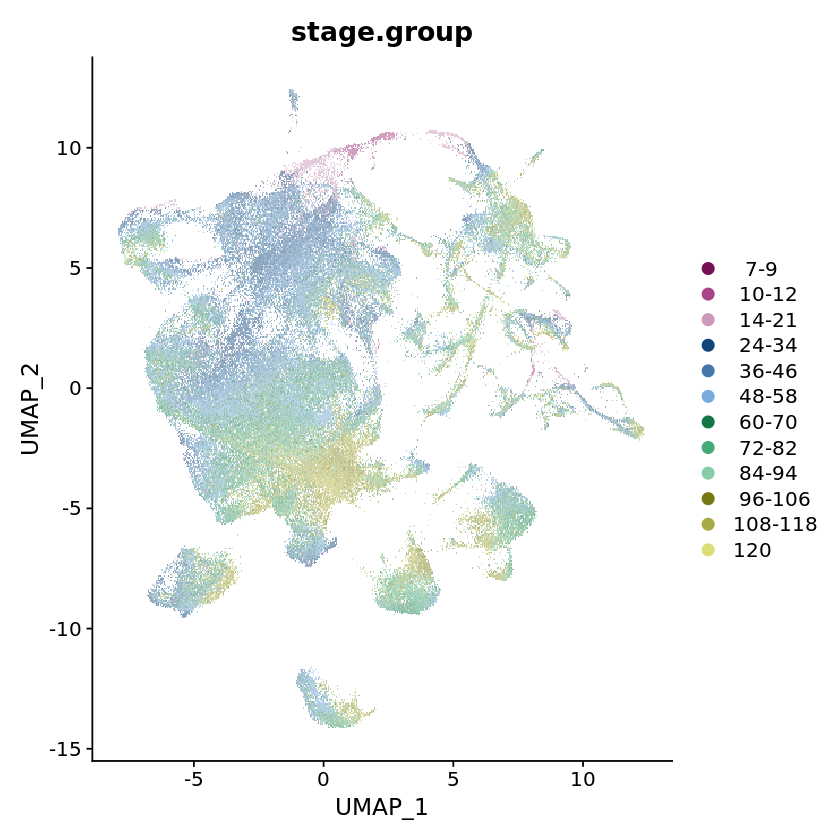

In [26]:

DimPlot(object = dat_sub, reduction = 'umap', pt.size = 0.5, cols = tol21rainbow[c(1:6,10:16)], group.by = "stage.group", shuffle = T)


##### Symp adrn marker gene expression

In [36]:
# load published developmental cell type marker gene lists for human fetal adrenal medullary cells from Kildisiute et al., Kameneva et al. and Jansky et al. translated to zebrafish
markers_hum <- read.delim("fetal_adrenal_markers_dr.csv", stringsAsFactors = F, sep = ",", header = T, row.names = NULL)

# convert to list
modules_pan <- as.list(markers_hum)
modules_pan <- lapply(modules_pan, function(X) X[X != ""])
modules_pan <- lapply(modules_pan, function(X) X[X %in% rownames(dat_sub)])

# make sure correct symbols are being used in gene names
modules_pan <- lapply(modules_pan, function(x) gsub("si\\.","si:",x))
modules_pan <- lapply(modules_pan, function(x) gsub("zgc\\.","zgc:",x))
modules_pan <- lapply(modules_pan, function(x) gsub("mt\\.","mt-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("dkey\\.","dkey-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("h211\\.","h211-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("1073\\.","1073-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("1073\\.","1073-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("ch73\\.","ch73-",x))
            
modules_pan <- modules_pan[lengths(modules_pan) >= 3]
                      

In [32]:
# get gene set expression scores
dat <- dat_sub

dat <- AddModuleScore(
  dat,
  features = modules_pan,
  name = names(modules_pan)
)

avexp_test <- as.data.frame(dat@meta.data)

# remove numbers from the module names
colnames(avexp_test) <- gsub('[0-9]+', '', colnames(avexp_test))

Warning message:
“Removed 10 rows containing missing values or values outside the scale range (`geom_point()`).”


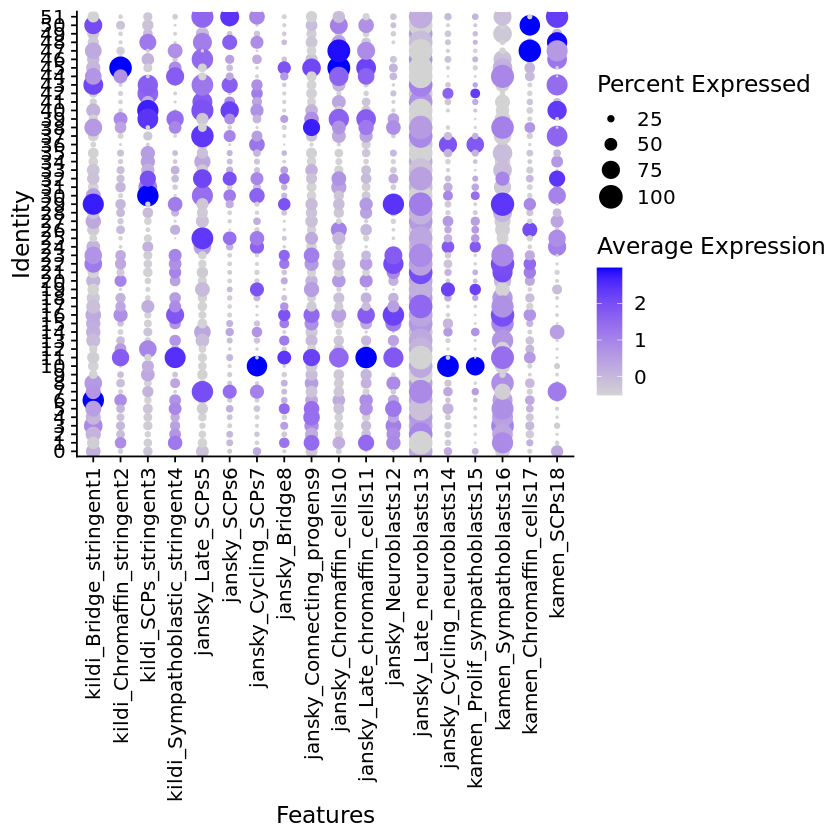

In [35]:
mod_names_numb <- paste0(colnames(markers_hum), c(1: length(colnames(markers_hum))))

DotPlot(dat, features = mod_names_numb, group.by = 'seurat_clusters',
    dot.min = 0.02,
    col.min = min(dat@meta.data[,mod_names_numb]),
    col.max = max(dat@meta.data[,mod_names_numb]))  +
theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1))

#### Find and write out cluster markers

In [ ]:
Idents(dat_sub)<- "seurat_clusters"

# plot markers:
markers_all <- FindAllMarkers(object = dat_sub, only.pos = TRUE, min.pct = 0.5, logfc.threshold = 0.8)

# Then print
write.csv(markers_all, file = paste0("clusterMarkersAll_",dat_name,"_seurclusts_minpct50_logfct_80.csv"))

#### assign symp adrn dev cell types

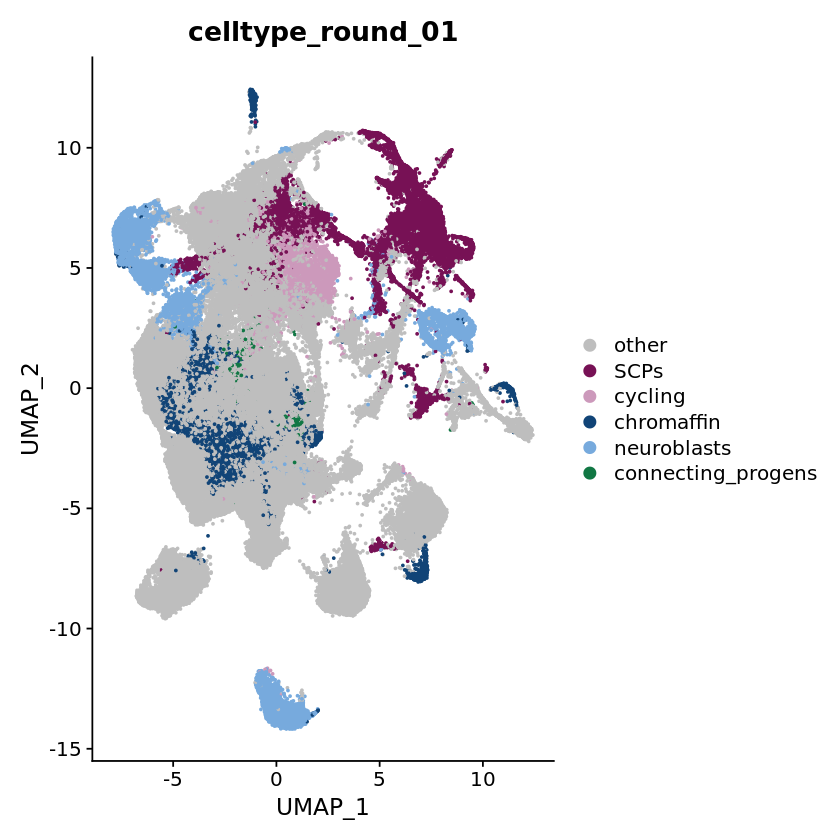

In [37]:
Idents(dat_sub) <- 'seurat_clusters'

dat_sub <- RenameIdents(object = dat_sub,
'0' = 'other',
'1' = 'other',
'2' = 'other',
'3' = 'other',
'4' = 'other',
'5' = 'other',
'6' = 'other',
'7' = 'SCPs',
'8' = 'other',
'9' = 'other',
'10' = 'cycling',
'11' = 'chromaffin',
'12' = 'other',
'13' = 'other',
'14' = 'other',
'15' = 'other',
'16' = 'chromaffin',
'17' = 'neuroblasts',
'18' = 'other',
'19' = 'other',
'20' = 'other',
'21' = 'neuroblasts',
'22' = 'neuroblasts',
'23' = 'neuroblasts',
'24' = 'SCPs',
'25' = 'SCPs',
'26' = 'other',
'27' = 'other',
'28' = 'other',
'29' = 'neuroblasts',
'30' = 'SCPs',
'31' = 'other',
'32' = 'SCPs',
'33' = 'other',
'34' = 'other',
'35' = 'other',
'36' = 'other',
'37' = 'SCPs',
'38' = 'connecting_progens',
'39' = 'chromaffin',
'40' = 'SCPs',
'41' = 'SCPs',
'42' = 'other',
'43' = 'SCPs',
'44' = 'chromaffin',
'45' = 'chromaffin',
'46' = 'SCPs',
'47' = 'chromaffin',
'48' = 'SCPs',
'49' = 'other',
'50' = 'other',
'51' = 'SCPs'
)

# save celltype information in the meta.data (in the column "celltype""
dat_sub$celltype_round_01 <- Idents(dat_sub)

DimPlot(object = dat_sub, reduction = 'umap', pt.size = 0.4, group.by = "celltype_round_01",
            cols = c('grey',tol21rainbow[c(1,3,4,6,10,12,13,15,16,18)]), shuffle = T, raster=FALSE)

In [ ]:
# save
saveRDS(dat_sub, paste0(dat_name,"_clustered.rds"))

### 2. subcluster potential symp adrn dev cells round 1

In [47]:
# reload and subset
dat_sub <- readRDS("daniocell_SAlin_clustered.Robj")

Idents(dat_sub) <- 'celltype_round_01'
dat_sub <- subset(x = dat_sub, idents = 'other', invert = T)

In [55]:
dat_name <- "daniocell_SAlin_01"

In [49]:
# normalise and scale
dat_sub <- NormalizeData(dat_sub)

all.genes <- rownames(x = dat_sub)
dat_sub <- ScaleData(object = dat_sub, features = all.genes)

Centering and scaling data matrix



In [50]:
# Variable genes

# Load genes associated with the cell cycle that should also be excluded for PCA and clustering
to.regress.cellcycle <- read.csv("zfish_prolif_markers.csv")
to.regress.cellcycle <- as.character(to.regress.cellcycle$x)


dat_sub <- FindVariableFeatures(object = dat_sub,selection.method = 'vst', nfeatures = 2000)
var_feats <- VariableFeatures(object = dat_sub)
var_feats <- var_feats[!var_feats %in% to.regress.cellcycle]

length(var_feats)

[1] 1989

PC_ 1 
Positive:  cldnh, epcam, wu:fj16a03, pvalb5, si:ch211-153b23.5, f11r.1, selenow2b, malb, anxa5b, gsnb 
	   cldnb, nqo1, si:dkey-247k7.2, cldne, aqp3a, fabp10b, spint2, vsig8a, zgc:158343, zgc:165423 
	   krt1-c5, bik, si:ch1073-443f11.2, krt18b, zgc:92313, gstp1, moxd1l, ompb, oclna, capn8 
Negative:  nrn1a, inab, hes6, dlb, tubb2, rbfox3a, si:ch211-57n23.4, LOC798783, cplx2l, nes 
	   CU634008.1, dla, hpca, phox2bb, XLOC-003692, abhd6a, si:ch73-21g5.7, im:7152348, her4.2, map1ab 
	   lin28a, pcp4a, stmn3, XLOC-003689, slc18a3a, her15.1, prph, zgc:158291, chodl, nefmb 
PC_ 2 
Positive:  pmp22a, col1a2, col5a1, col1a1b, col1a1a, tpm4a, sparc, col5a2a, zgc:162730, krt8 
	   col6a2, dcn, col2a1b, bhmt, hand2, col6a1, col6a3, cyr61, si:dkey-261h17.1, krt18a.1 
	   rbp4, col12a1a, twist1a, lum, fmoda, col6a4a, postnb, lrrc17, pcolcea, socs3a 
Negative:  pvalb5, cldnh, si:ch211-153b23.5, fabp10b, selenow2b, malb, vsig8a, ompb, zgc:165423, cldne 
	   moxd1l, XLOC-024343, si:dkey-247k7.

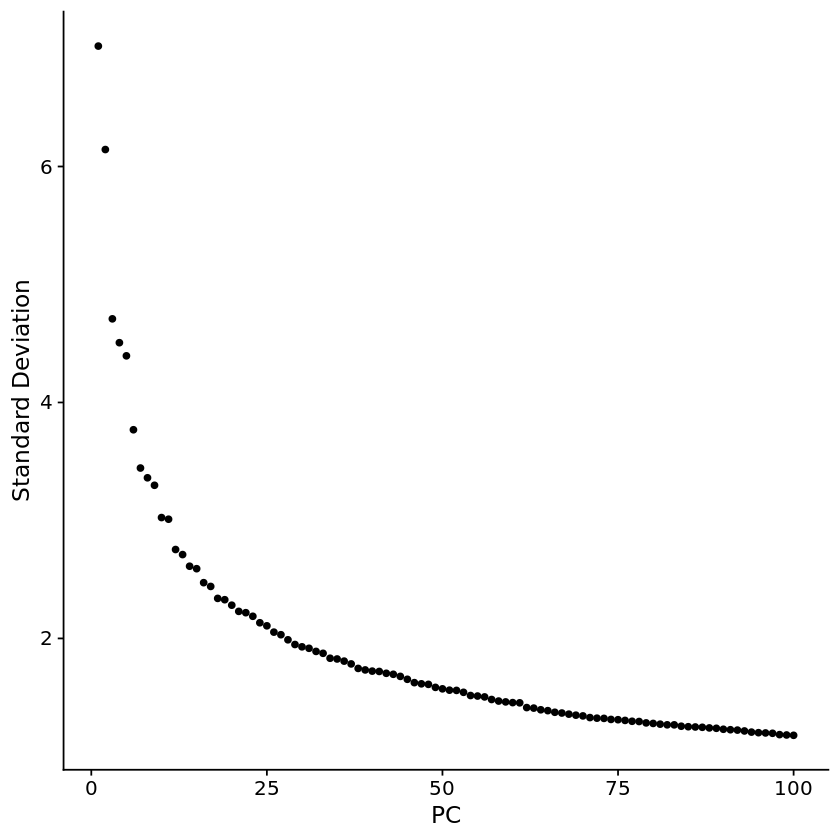

In [51]:
# PCA
dat_sub <- RunPCA(dat_sub, features = var_feats, npcs = 100)

ElbowPlot(object = dat_sub, ndims = 100)


In [53]:
# Cluster and UMAP

# Set number of principal components to use
ndims <- 36

# Clustering
k <- round(max(20,sqrt(ncol(dat_sub)))/4)
if(k %% 2 == 0) {k <- k+1}
if(k > 41) {k <- 41}

dat_sub <- FindNeighbors(object = dat_sub, dims = 1:ndims, k.param = k)
dat_sub <- FindClusters(object = dat_sub, resolution = 1.1)

dat_sub <- RunUMAP(dat_sub, reduction = "pca", dims = 1:ndims)

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 46368
Number of edges: 3231202

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9143
Number of communities: 40
Elapsed time: 14 seconds


09:57:28 UMAP embedding parameters a = 0.9922 b = 1.112

Found more than one class "dist" in cache; using the first, from namespace 'spam'

Also defined by ‘BiocGenerics’

09:57:28 Read 46368 rows and found 36 numeric columns

09:57:28 Using Annoy for neighbor search, n_neighbors = 30

Found more than one class "dist" in cache; using the first, from namespace 'spam'

Also defined by ‘BiocGenerics’

09:57:29 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

09:57:32 Writing NN index file to temp file /tmp/RtmpxTi5qa/file3e8b693edc4183

09:57:32 Searching Annoy index using 1 thread, search_k = 3000

09:57:44 Annoy recall = 100%

09:57:46 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

09:57:48 Initializing from normalized Laplacian 

#### Plot

##### UMAP

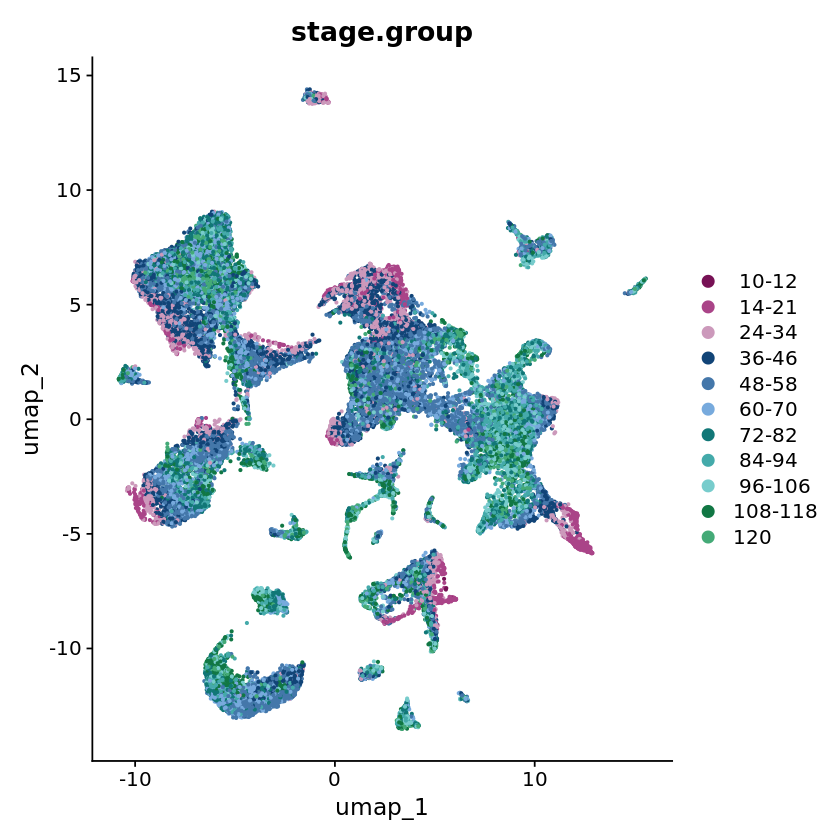

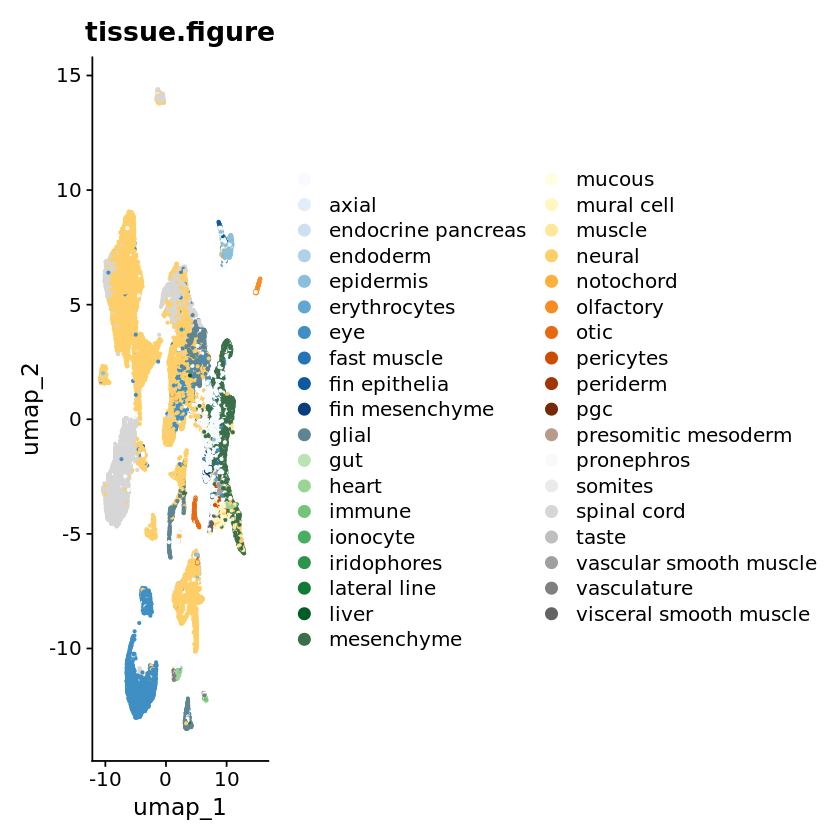

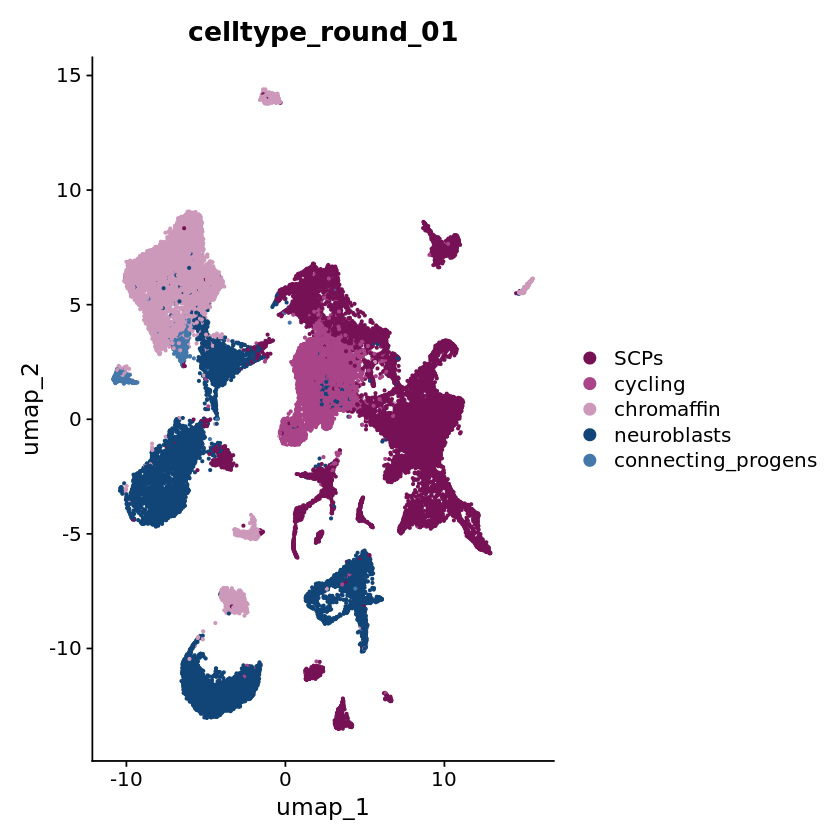

In [57]:
coul <- c(brewer.pal(9, "Blues"),
          brewer.pal(9, "Greens")[3:9],
          brewer.pal(9, "YlOrBr")[1:9],
          brewer.pal(9, "Greys")[1:9]
          )

coul_long <- colorRampPalette(coul)(40)

DimPlot(object = dat_sub, reduction = 'umap', pt.size = 0.5, cols = tol21rainbow, group.by = "stage.group", shuffle = T)

DimPlot(object = dat_sub, reduction = 'umap', pt.size = 0.5, cols = coul_long, group.by = "tissue.figure", shuffle = T)

DimPlot(object = dat_sub, reduction = 'umap', pt.size = 0.5, cols = tol21rainbow, group.by = "celltype_round_01", shuffle = T)


##### symp adrn gene expression

In [58]:
# load published developmental cell type marker gene lists for human fetal adrenal medullary cells from Kildisiute et al., Kameneva et al. and Jansky et al. translated to zebrafish
markers_hum <- read.delim("fetal_adrenal_markers_dr.csv", stringsAsFactors = F, sep = ",", header = T, row.names = NULL)

# convert to list
modules_pan <- as.list(markers_hum)
modules_pan <- lapply(modules_pan, function(X) X[X != ""])
modules_pan <- lapply(modules_pan, function(X) X[X %in% rownames(dat_sub)])

# make sure correct symbols are being used in gene names
modules_pan <- lapply(modules_pan, function(x) gsub("si\\.","si:",x))
modules_pan <- lapply(modules_pan, function(x) gsub("zgc\\.","zgc:",x))
modules_pan <- lapply(modules_pan, function(x) gsub("mt\\.","mt-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("dkey\\.","dkey-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("h211\\.","h211-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("1073\\.","1073-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("1073\\.","1073-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("ch73\\.","ch73-",x))
            
modules_pan <- modules_pan[lengths(modules_pan) >= 3]

In [59]:
# get gene set expression scores
dat <- dat_sub

dat <- AddModuleScore(
  dat,
  features = modules_pan,
  name = names(modules_pan)
)

avexp_test <- as.data.frame(dat@meta.data)

# remove numbers from the module names
colnames(avexp_test) <- gsub('[0-9]+', '', colnames(avexp_test))

Warning message:
“Removed 27 rows containing missing values or values outside the scale range (`geom_point()`).”


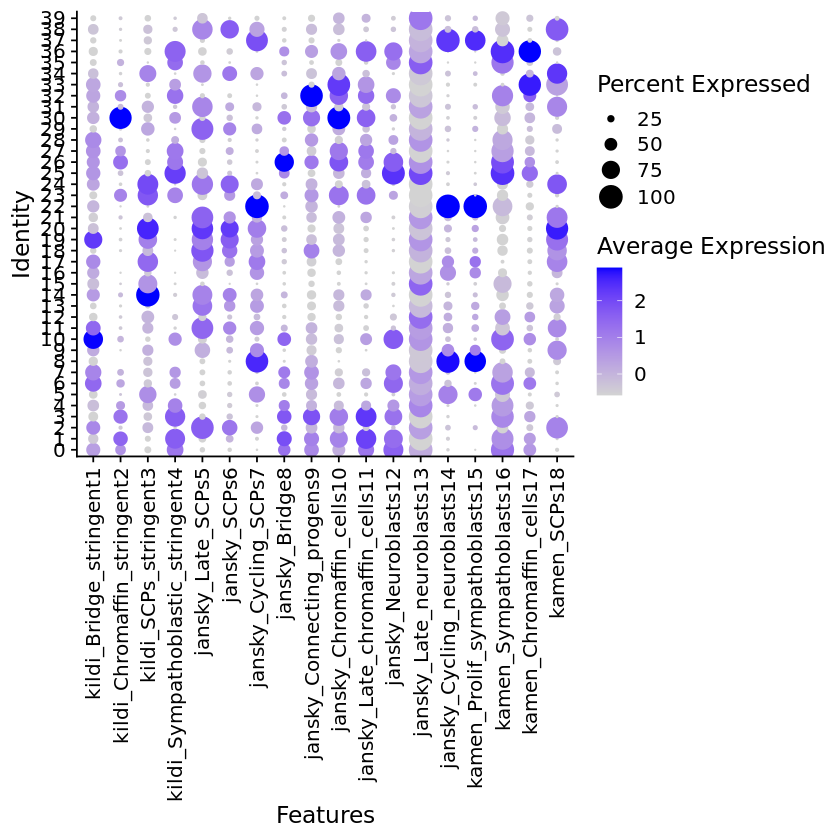

In [60]:
mod_names_numb <- paste0(colnames(markers_hum), c(1: length(colnames(markers_hum))))

DotPlot(dat, features = mod_names_numb, group.by = 'seurat_clusters',
    dot.min = 0.02,
    col.min = min(dat@meta.data[,mod_names_numb]),
    col.max = max(dat@meta.data[,mod_names_numb]))  +
theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1))

#### Find and write out cluster markers

In [ ]:
Idents(dat_sub)<- "seurat_clusters"

# plot markers:
markers_all <- FindAllMarkers(object = dat_sub, only.pos = TRUE, min.pct = 0.5, logfc.threshold = 0.8)

# Then print
write.csv(markers_all, file = paste0("clusterMarkersAll_",dat_name,"_seurclusts_minpct50_logfct_80.csv"))

#### assign symp adrn dev cell types

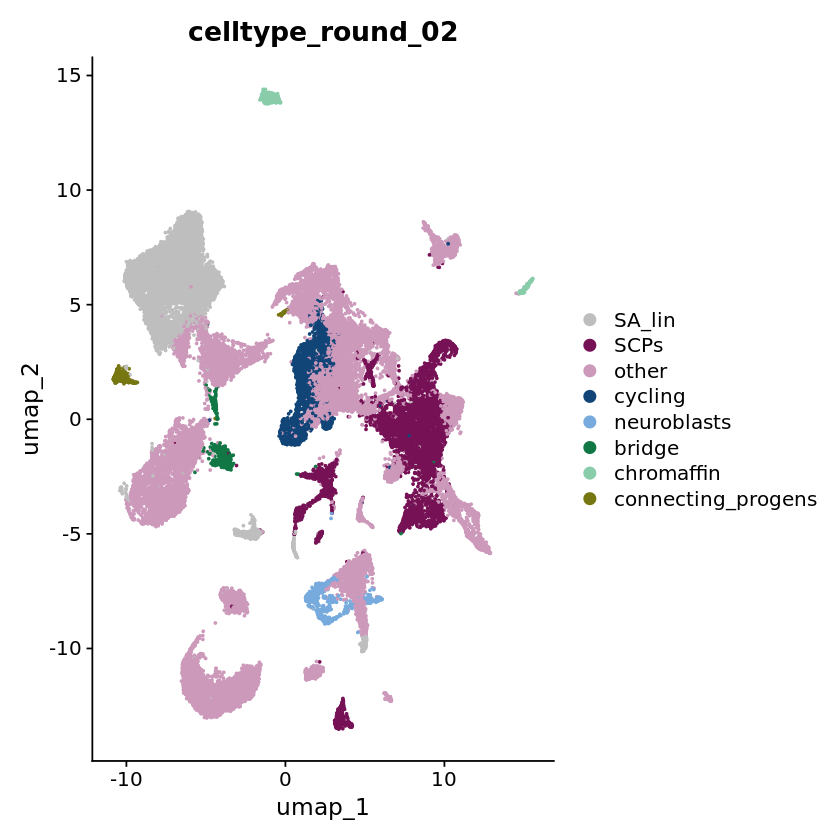

In [61]:
Idents(dat_sub) <- 'seurat_clusters'

dat_sub <- RenameIdents(object = dat_sub,
    '0' = 'SA_lin',
    '1' = 'SA_lin',
    '2' = 'SCPs',
    '3' = 'SA_lin',
    '4' = 'other',
    '5' = 'other',
    '6' = 'other',
    '7' = 'other',
    '8' = 'cycling',
    '9' = 'other',
    '10' = 'other',
    '11' = 'SCPs',
    '12' = 'other',
    '13' = 'other',
    '14' = 'other',
    '15' = 'other',
    '16' = 'other',
    '17' = 'other',
    '18' = 'SCPs',
    '19' = 'SCPs',
    '20' = 'SCPs',
    '21' = 'other',
    '22' = 'cycling',
    '23' = 'other',
    '24' = 'SCPs',
    '25' = 'neuroblasts',
    '26' = 'bridge',
    '27' = 'SA_lin',
    '28' = 'other',
    '29' = 'other',
    '30' = 'chromaffin',
    '31' = 'other',
    '32' = 'connecting_progens',
    '33' = 'chromaffin',
    '34' = 'other',
    '35' = 'neuroblasts',
    '36' = 'SA_lin',
    '37' = 'cycling',
    '38' = 'SCPs',
    '39' = 'other'
)

# save celltype information in the meta.data (in the column "celltype""
dat_sub$celltype_round_02 <- Idents(dat_sub)

DimPlot(object = dat_sub, reduction = 'umap', pt.size = 0.4, group.by = "celltype_round_02",
            cols = c('grey',tol21rainbow[c(1,3,4,6,10,12,13,15,16,18)]), shuffle = T, raster=FALSE)

In [63]:
# save object
saveRDS(dat_sub, paste0(dat_name,"_clustered.rds"))

### 3. subcluster potential symp adrn dev cells round 2

In [ ]:

dat_sub <- readRDS("daniocell_SAlin_01_clustered.rds")

In [64]:
## subset
dat_name <- "daniocell_SAlin_02"

Idents(dat_sub) <- 'celltype_round_02'
dat_sub <- subset(x = dat_sub, idents = 'other', invert = T)


In [65]:
# normalise and scale
dat_sub <- NormalizeData(dat_sub)

all.genes <- rownames(x = dat_sub)
dat_sub <- ScaleData(object = dat_sub, features = all.genes)

Centering and scaling data matrix



In [66]:
# Variable genes

# Load genes associated with the cell cycle that should also be excluded for PCA and clustering
to.regress.cellcycle <- read.csv("zfish_prolif_markers.csv")
to.regress.cellcycle <- as.character(to.regress.cellcycle$x)


dat_sub <- FindVariableFeatures(object = dat_sub,selection.method = 'vst', nfeatures = 2000)
var_feats <- VariableFeatures(object = dat_sub)
var_feats <- var_feats[!var_feats %in% to.regress.cellcycle]

length(var_feats)

[1] 1983

PC_ 1 
Positive:  pvalb5, cldnh, si:ch211-153b23.5, selenow2b, fabp10b, malb, zgc:165423, vsig8a, moxd1l, ompb 
	   cldne, krt1-c5, si:dkey-247k7.2, epcam, gsnb, bik, cldnb, cldn8, svopl, XLOC-024343 
	   wu:fj16a03, si:rp71-17i16.6, zgc:92313, cnga4, capn8, GBGT1 (1 of many), si:ch1073-443f11.2, si:ch211-243g18.2, elf3, f11r.1 
Negative:  LOC100537384, nrn1a, rbfox3a, CU634008.1, hes6, dlb, dla, meis2b, mab21l2, slc6a1b 
	   tubb2, LOC798783, im:7152348, hpca, pcp4a, abhd6a, her4.2, XLOC-003692, lmo3, gadd45gb.1 
	   map1ab, scrt1a, inab, hes2.2, si:ch211-69g19.2, lin28a, hist1h4l, si:ch73-21g5.7, neurod4, vamp1 
PC_ 2 
Positive:  pmp22a, sparc, col1a2, krt8, col5a1, tpm4a, zgc:162730, krt18a.1, col1a1b, col1a1a 
	   col5a2a, bhmt, col2a1b, col6a2, dcn, col6a1, hand2, rbp4, col6a3, si:dkey-261h17.1 
	   col12a1a, cyr61, krt18b, socs3a, twist1a, jun, cebpd, fmoda, lum, cpn1 
Negative:  calm1b, cplx2l, tubb2, stmn4l, uchl1, map1ab, pkma, nrn1a, chga, nrsn1 
	   hpca, rbfox3a, si:dkey-46

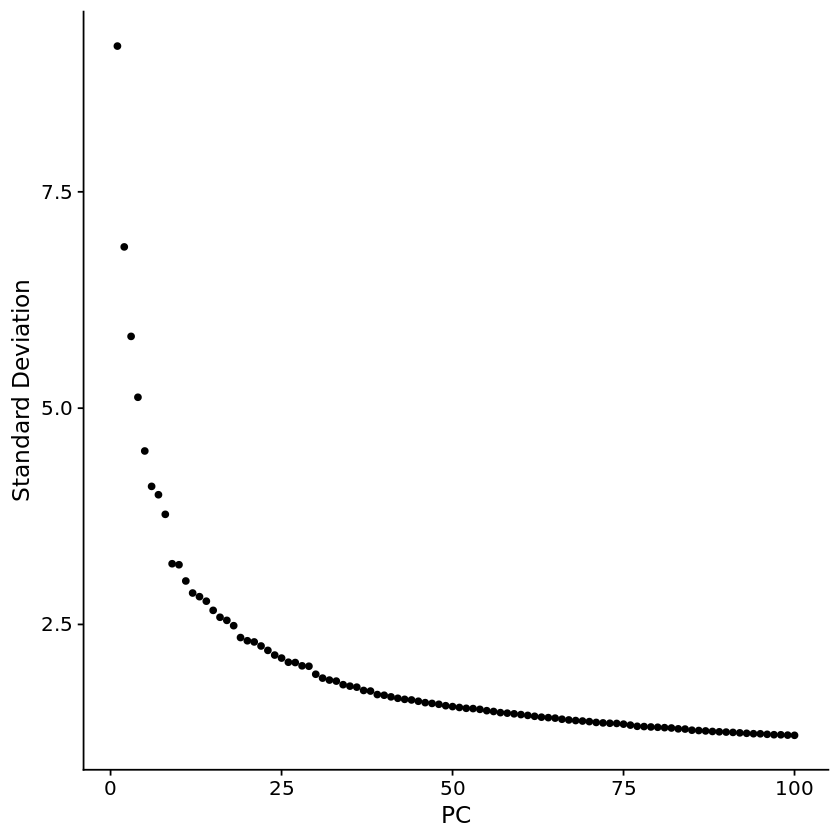

In [67]:
# PCA
dat_sub <- RunPCA(dat_sub, features = var_feats, npcs = 100)

ElbowPlot(object = dat_sub, ndims = 100)


In [68]:
# Cluster and UMAP

# Set number of principal components to use
ndims <- 30

# Clustering
k <- round(max(20,sqrt(ncol(dat_sub)))/4)
if(k %% 2 == 0) {k <- k+1}
if(k > 41) {k <- 41}

dat_sub <- FindNeighbors(object = dat_sub, dims = 1:ndims, k.param = k)
dat_sub <- FindClusters(object = dat_sub, resolution = 1.1)

dat_sub <- RunUMAP(dat_sub, reduction = "pca", dims = 1:ndims)

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 23538
Number of edges: 1736488

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8886
Number of communities: 29
Elapsed time: 4 seconds


10:12:31 UMAP embedding parameters a = 0.9922 b = 1.112

Found more than one class "dist" in cache; using the first, from namespace 'spam'

Also defined by ‘BiocGenerics’

10:12:31 Read 23538 rows and found 30 numeric columns

10:12:31 Using Annoy for neighbor search, n_neighbors = 30

Found more than one class "dist" in cache; using the first, from namespace 'spam'

Also defined by ‘BiocGenerics’

10:12:31 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

10:12:32 Writing NN index file to temp file /tmp/RtmpxTi5qa/file3e8b691cb44c82

10:12:32 Searching Annoy index using 1 thread, search_k = 3000

10:12:38 Annoy recall = 100%

10:12:41 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

10:12:43 Initializing from normalized Laplacian 

#### Plot

##### UMAP

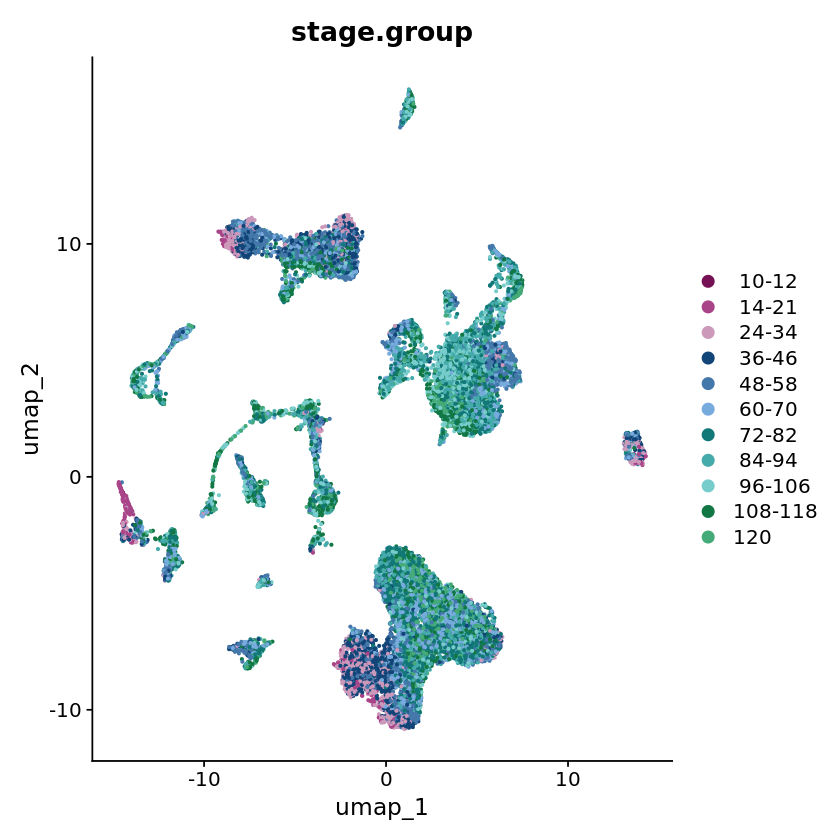

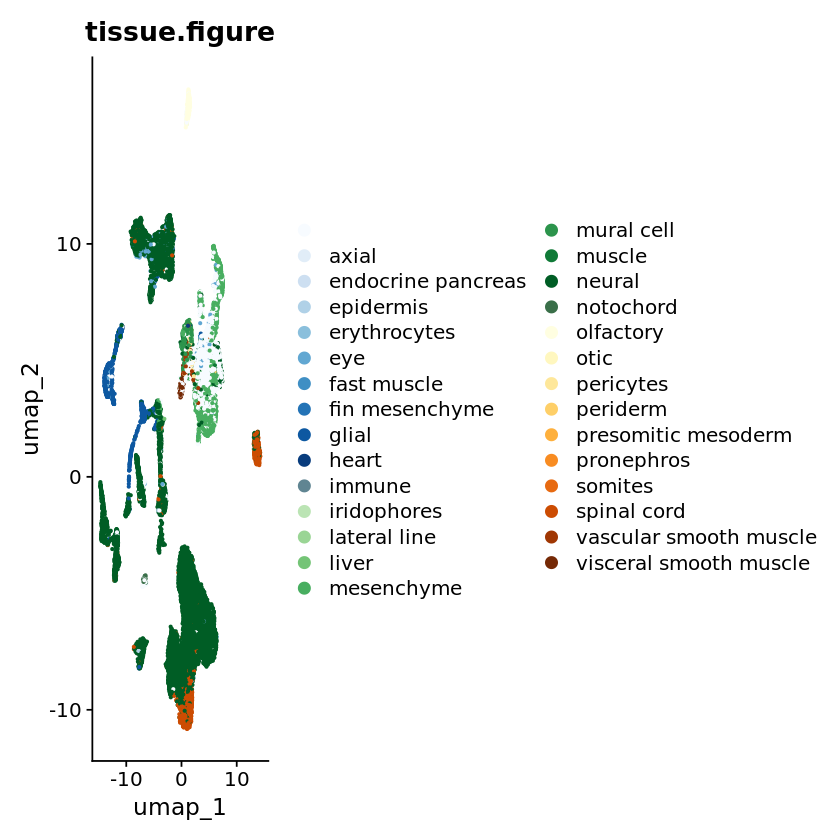

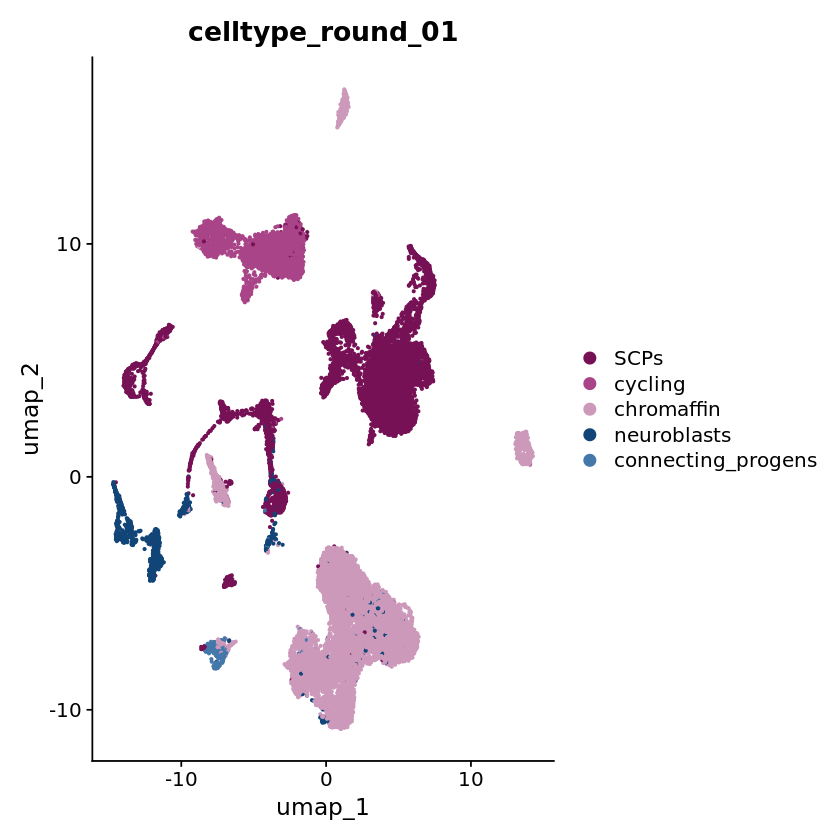

In [69]:
coul <- c(brewer.pal(9, "Blues"),
          brewer.pal(9, "Greens")[3:9],
          brewer.pal(9, "YlOrBr")[1:9],
          brewer.pal(9, "Greys")[1:9]
          )

coul_long <- colorRampPalette(coul)(40)

DimPlot(object = dat_sub, reduction = 'umap', pt.size = 0.5, cols = tol21rainbow, group.by = "stage.group", shuffle = T)

DimPlot(object = dat_sub, reduction = 'umap', pt.size = 0.5, cols = coul_long, group.by = "tissue.figure", shuffle = T)

DimPlot(object = dat_sub, reduction = 'umap', pt.size = 0.5, cols = tol21rainbow, group.by = "celltype_round_01", shuffle = T)


##### symp adrn gene expression

In [70]:
# load published developmental cell type marker gene lists for human fetal adrenal medullary cells from Kildisiute et al., Kameneva et al. and Jansky et al. translated to zebrafish
markers_hum <- read.delim("fetal_adrenal_markers_dr.csv", stringsAsFactors = F, sep = ",", header = T, row.names = NULL)

# convert to list
modules_pan <- as.list(markers_hum)
modules_pan <- lapply(modules_pan, function(X) X[X != ""])
modules_pan <- lapply(modules_pan, function(X) X[X %in% rownames(dat_sub)])

# make sure correct symbols are being used in gene names
modules_pan <- lapply(modules_pan, function(x) gsub("si\\.","si:",x))
modules_pan <- lapply(modules_pan, function(x) gsub("zgc\\.","zgc:",x))
modules_pan <- lapply(modules_pan, function(x) gsub("mt\\.","mt-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("dkey\\.","dkey-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("h211\\.","h211-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("1073\\.","1073-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("1073\\.","1073-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("ch73\\.","ch73-",x))
            
modules_pan <- modules_pan[lengths(modules_pan) >= 3]

In [71]:
# get gene set expression scores
dat <- dat_sub

dat <- AddModuleScore(
  dat,
  features = modules_pan,
  name = names(modules_pan)
)

avexp_test <- as.data.frame(dat@meta.data)

# remove numbers from the module names
colnames(avexp_test) <- gsub('[0-9]+', '', colnames(avexp_test))

Warning message:
“Removed 24 rows containing missing values or values outside the scale range (`geom_point()`).”


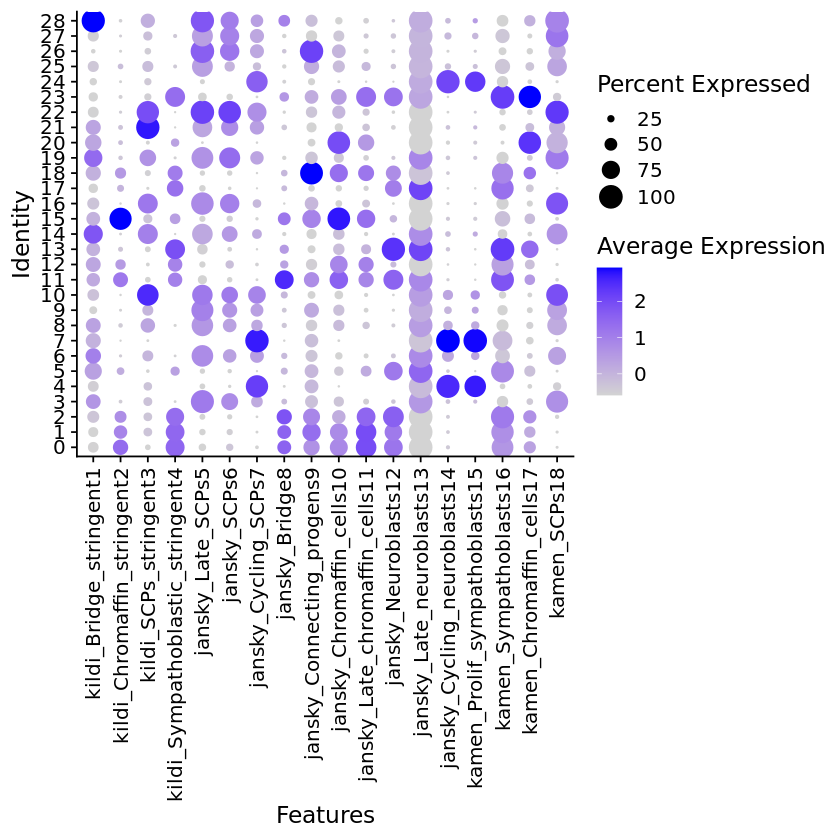

In [72]:
mod_names_numb <- paste0(colnames(markers_hum), c(1: length(colnames(markers_hum))))

DotPlot(dat, features = mod_names_numb, group.by = 'seurat_clusters',
    dot.min = 0.02,
    col.min = min(dat@meta.data[,mod_names_numb]),
    col.max = max(dat@meta.data[,mod_names_numb]))  +
theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1))

##### individual marker genes

Warning message:
“Removed 129 rows containing missing values or values outside the scale range (`geom_point()`).”


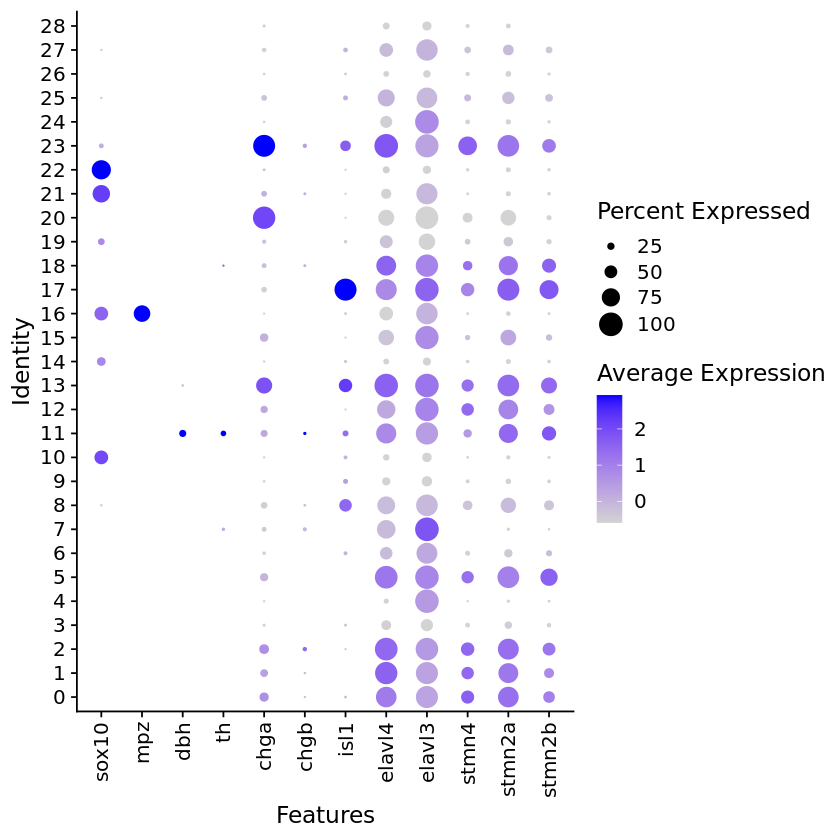

In [75]:
mods_plot <- c('sox10','mpz','dbh','th','chga','chgb','isl1','elavl4','elavl3','stmn4','stmn2a','stmn2b')
mods_plot <- mods_plot[mods_plot %in% rownames(dat)]

DotPlot(dat, features = mods_plot, group.by = 'seurat_clusters',
        dot.min = 0.02,
        col.min = min(dat@meta.data[,mod_names_numb]),
        col.max = max(dat@meta.data[,mod_names_numb]))  +
theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1))

#### Find and write out cluster markers

In [ ]:
Idents(dat_sub)<- "seurat_clusters"

# plot markers:
markers_all <- FindAllMarkers(object = dat_sub, only.pos = TRUE, min.pct = 0.5, logfc.threshold = 0.8)

# Then print
write.csv(markers_all, file = paste0("clusterMarkersAll_",dat_name,"_seurclusts_minpct50_logfct_80.csv")

### 4. subcluster again (round 3) focusing on clusters with expected individual marker expression

In [76]:
dat_name <- "daniocell_SAlin_03"

Idents(dat_sub) <- 'seurat_clusters'
dat_sub <- subset(dat_sub, idents = c(10, 11, 12, 13, 16, 17, 21, 22, 23))

In [77]:
# normalise and scale
dat_sub <- NormalizeData(dat_sub)

all.genes <- rownames(x = dat_sub)
dat_sub <- ScaleData(object = dat_sub, features = all.genes)


Centering and scaling data matrix



In [78]:
# Variable genes

# Load genes associated with the cell cycle that should also be excluded for PCA and clustering
to.regress.cellcycle <- read.csv("zfish_prolif_markers.csv")
to.regress.cellcycle <- as.character(to.regress.cellcycle$x)


dat_sub <- FindVariableFeatures(object = dat_sub,selection.method = 'vst', nfeatures = 2000)
var_feats <- VariableFeatures(object = dat_sub)
var_feats <- var_feats[!var_feats %in% to.regress.cellcycle]

length(var_feats)

[1] 1955

PC_ 1 
Positive:  stmn2a, calm1b, snap25a, ywhag2, eno2, tmsb2, syt2a, nptna, ndrg3a, sncgb 
	   atp2b3b, gng3, olfm1b, scn8ab, hpca, ank2a, uchl1, cplx2l, gapdhs, adam11 
	   nrn1a, eno1a, vamp1, scn8aa, tuba1a, adam23a, stmn4l, snap25b, kcnab2a, fgf13a 
Negative:  qki2, zwi, cldn19, cldnk, mag, timd4, cdhr5a, elovl1b, si:ch73-335m24.2, ugt8 
	   si:dkey-204f11.64, cd59, si:ch211-156j16.1, fabp2, si:rp71-19m20.1, mbpb, si:dkey-164f24.2, cd82a, zgc:112994, cd226 
	   plp1b, mbpa, tlcd1, plekha1a, elovl7a, ppp1r14aa, tmem125b, si:dkey-200l5.4, lim2.2, tjp2b 
PC_ 2 
Positive:  cldnk, cd59, mbpb, mbpa, ppp1r14aa, mag, si:rp71-19m20.1, si:dkey-164f24.2, elovl1b, cldn19 
	   lgi2b, fabp2, zwi, si:ch73-335m24.2, cdhr5a, tlcd1, plp1b, si:ch211-156j16.1, timd4, cd226 
	   si:dkey-200l5.4, qki2, elovl7a, slc44a1b, ywhag1, zgc:112994, cd9b, anxa13l, crp1, tmem125b 
Negative:  tspan18a, hand2, gng8, zic1, her15.1, zic2a, insm1b, zic3, her6, dlb 
	   CR812832.1, nhlh2, bcl11ba, nwd2, etv1, irx1b, 

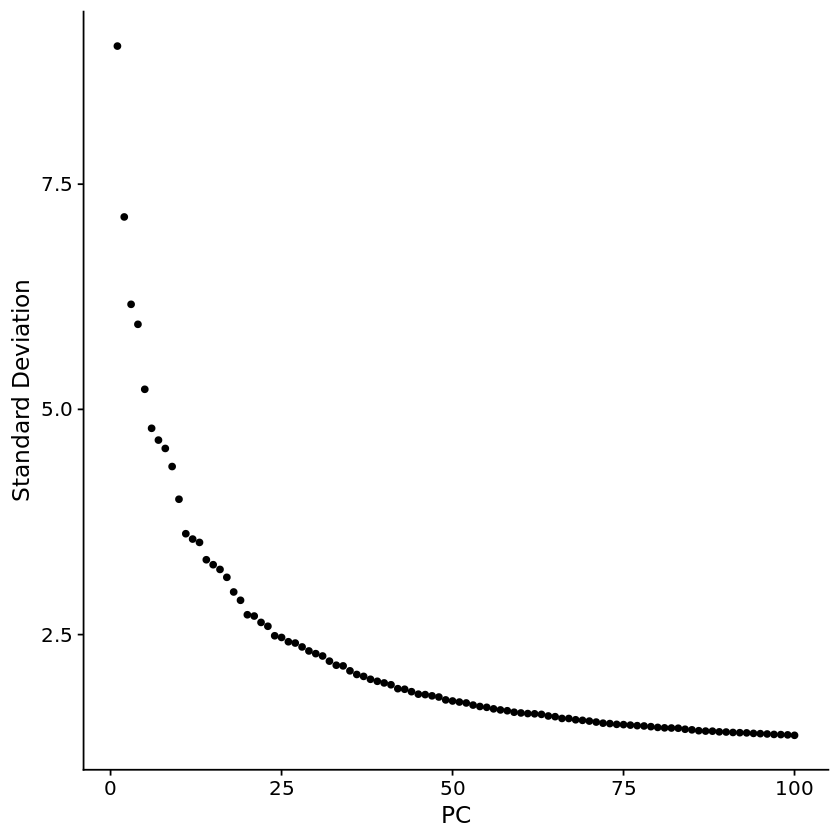

In [80]:
# PCA
dat_sub <- RunPCA(dat_sub, features = var_feats, npcs = 100)

ElbowPlot(object = dat_sub, ndims = 100)


In [81]:
# Cluster and UMAP

# Set number of principal components to use
ndims <- 25

# Clustering
k <- round(max(20,sqrt(ncol(dat_sub)))/4)
if(k %% 2 == 0) {k <- k+1}
if(k > 41) {k <- 41}

dat_sub <- FindNeighbors(object = dat_sub, dims = 1:ndims, k.param = k)
dat_sub <- FindClusters(object = dat_sub, resolution = 1.1)

dat_sub <- RunUMAP(dat_sub, reduction = "pca", dims = 1:ndims)

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 3538
Number of edges: 85021

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8982
Number of communities: 27
Elapsed time: 0 seconds


10:24:10 UMAP embedding parameters a = 0.9922 b = 1.112

Found more than one class "dist" in cache; using the first, from namespace 'spam'

Also defined by ‘BiocGenerics’

10:24:10 Read 3538 rows and found 25 numeric columns

10:24:10 Using Annoy for neighbor search, n_neighbors = 30

Found more than one class "dist" in cache; using the first, from namespace 'spam'

Also defined by ‘BiocGenerics’

10:24:10 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

10:24:11 Writing NN index file to temp file /tmp/RtmpxTi5qa/file3e8b6971bf93af

10:24:11 Searching Annoy index using 1 thread, search_k = 3000

10:24:12 Annoy recall = 100%

10:24:13 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

10:24:14 Initializing from normalized Laplacian +

#### Plot

##### UMAP

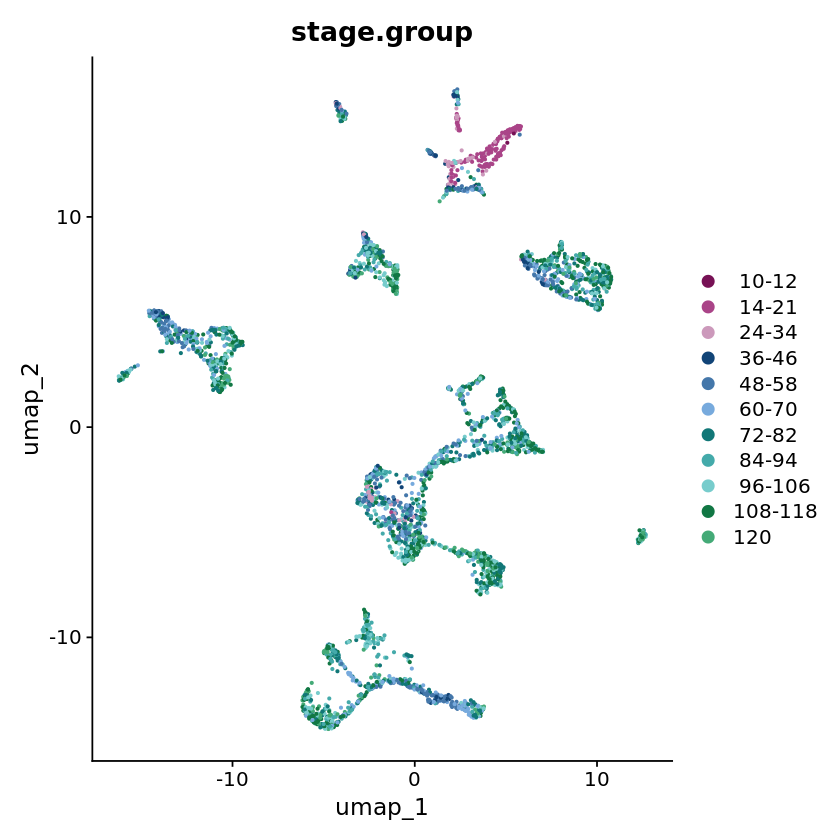

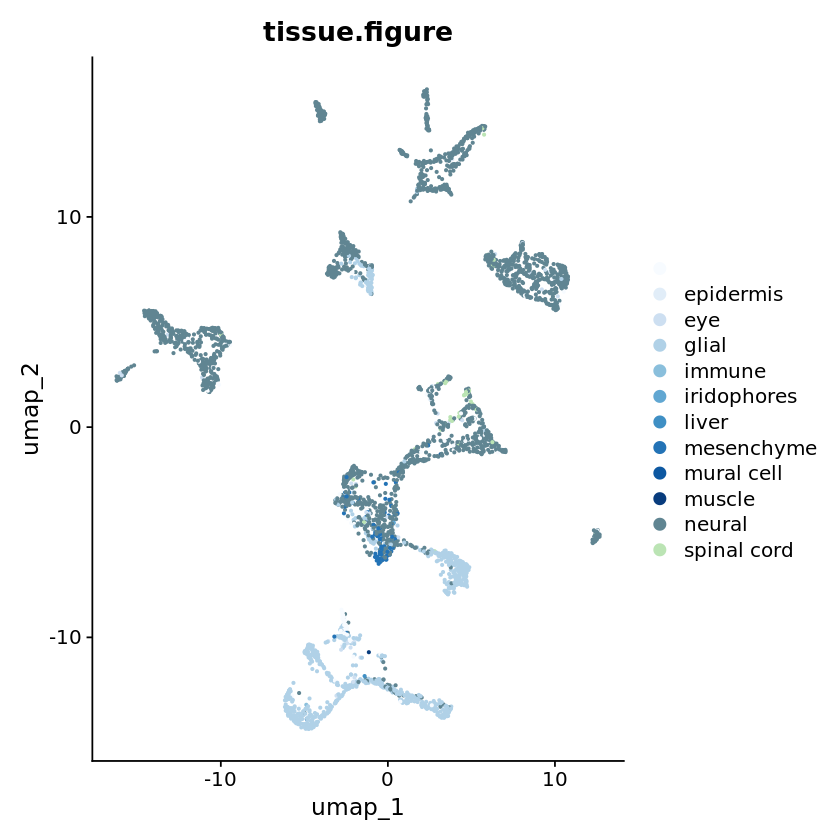

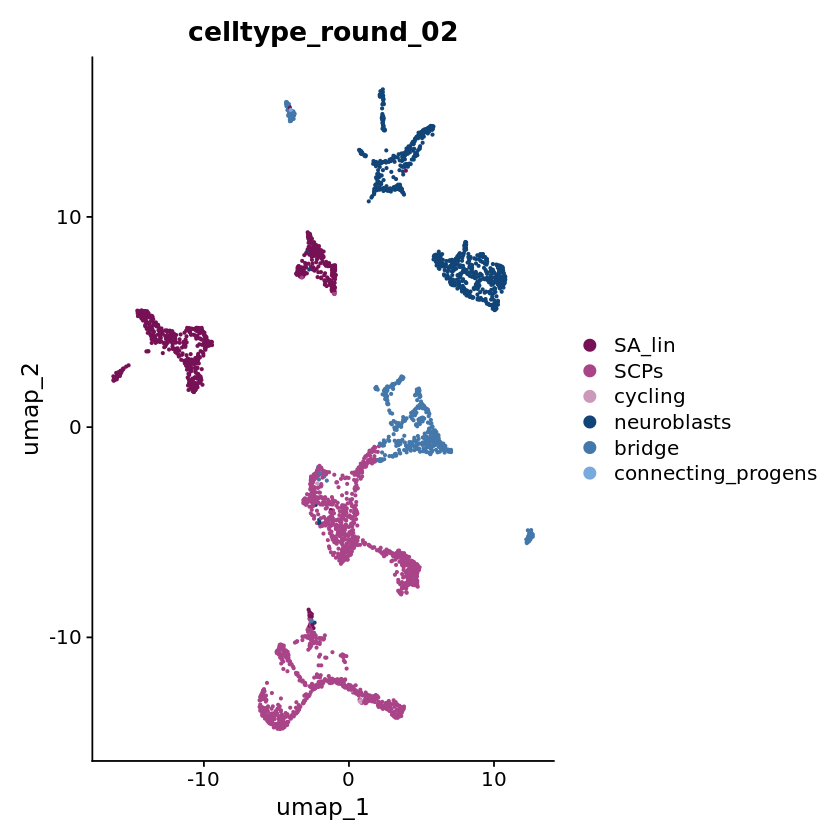

In [82]:
coul <- c(brewer.pal(9, "Blues"),
          brewer.pal(9, "Greens")[3:9],
          brewer.pal(9, "YlOrBr")[1:9],
          brewer.pal(9, "Greys")[1:9]
          )

coul_long <- colorRampPalette(coul)(40)

DimPlot(object = dat_sub, reduction = 'umap', pt.size = 0.5, cols = tol21rainbow, group.by = "stage.group", shuffle = T)

DimPlot(object = dat_sub, reduction = 'umap', pt.size = 0.5, cols = coul_long, group.by = "tissue.figure", shuffle = T)

DimPlot(object = dat_sub, reduction = 'umap', pt.size = 0.5, cols = tol21rainbow, group.by = "celltype_round_02", shuffle = T)


##### symp adrn gene expression

In [84]:
# load published developmental cell type marker gene lists for human fetal adrenal medullary cells from Kildisiute et al., Kameneva et al. and Jansky et al. translated to zebrafish
markers_hum <- read.delim("fetal_adrenal_markers_dr.csv", stringsAsFactors = F, sep = ",", header = T, row.names = NULL)

# convert to list
modules_pan <- as.list(markers_hum)
modules_pan <- lapply(modules_pan, function(X) X[X != ""])
modules_pan <- lapply(modules_pan, function(X) X[X %in% rownames(dat_sub)])

# make sure correct symbols are being used in gene names
modules_pan <- lapply(modules_pan, function(x) gsub("si\\.","si:",x))
modules_pan <- lapply(modules_pan, function(x) gsub("zgc\\.","zgc:",x))
modules_pan <- lapply(modules_pan, function(x) gsub("mt\\.","mt-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("dkey\\.","dkey-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("h211\\.","h211-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("1073\\.","1073-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("1073\\.","1073-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("ch73\\.","ch73-",x))
            
modules_pan <- modules_pan[lengths(modules_pan) >= 3]

In [85]:
# get gene set expression scores
dat <- dat_sub

dat <- AddModuleScore(
  dat,
  features = modules_pan,
  name = names(modules_pan)
)

avexp_test <- as.data.frame(dat@meta.data)

# remove numbers from the module names
colnames(avexp_test) <- gsub('[0-9]+', '', colnames(avexp_test))

Warning message:
“Removed 40 rows containing missing values or values outside the scale range (`geom_point()`).”


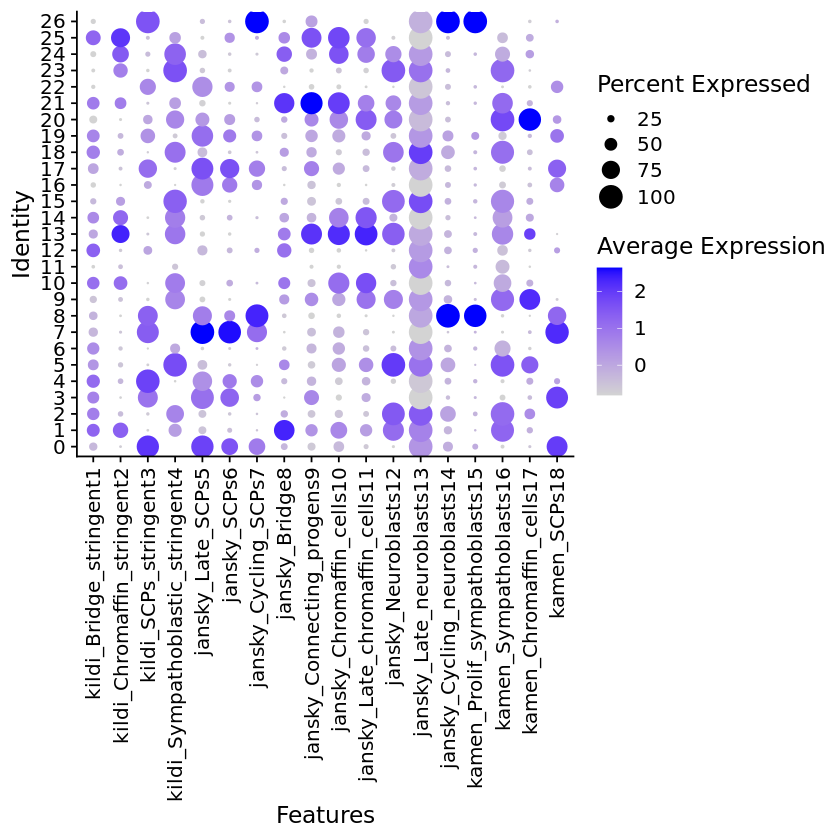

In [86]:
mod_names_numb <- paste0(colnames(markers_hum), c(1: length(colnames(markers_hum))))

DotPlot(dat, features = mod_names_numb, group.by = 'seurat_clusters',
    dot.min = 0.02,
    col.min = min(dat@meta.data[,mod_names_numb]),
    col.max = max(dat@meta.data[,mod_names_numb]))  +
theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1))

##### individual marker genes

Warning message:
“Removed 211 rows containing missing values or values outside the scale range (`geom_point()`).”


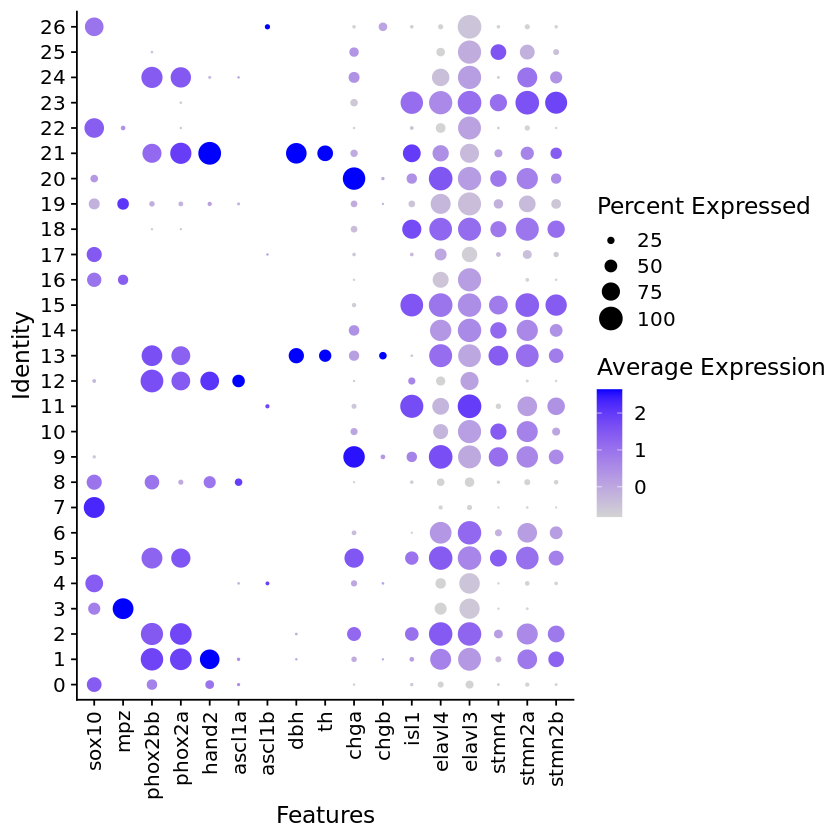

In [87]:
mods_plot <- c('sox10','mpz','phox2bb', 'phox2a','hand2','ascl1a','ascl1b','dbh','th','chga','chgb','isl1','elavl4','elavl3','stmn4','stmn2a','stmn2b')
mods_plot <- mods_plot[mods_plot %in% rownames(dat_sub)]

DotPlot(dat_sub, features = mods_plot, group.by = 'seurat_clusters',
    dot.min = 0.02,
    col.min = min(dat@meta.data[,mod_names_numb]),
    col.max = max(dat@meta.data[,mod_names_numb]))  +
theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1))

#### Find and write out cluster markers

In [ ]:
Idents(dat_sub)<- "seurat_clusters"

# plot markers:
markers_all <- FindAllMarkers(object = dat_sub, only.pos = TRUE, min.pct = 0.5, logfc.threshold = 0.8)

# Then print
write.csv(markers_all, file = paste0("clusterMarkersAll_",dat_name,"_seurclusts_minpct50_logfct_80.csv"))

#### assign symp adrn dev cell types

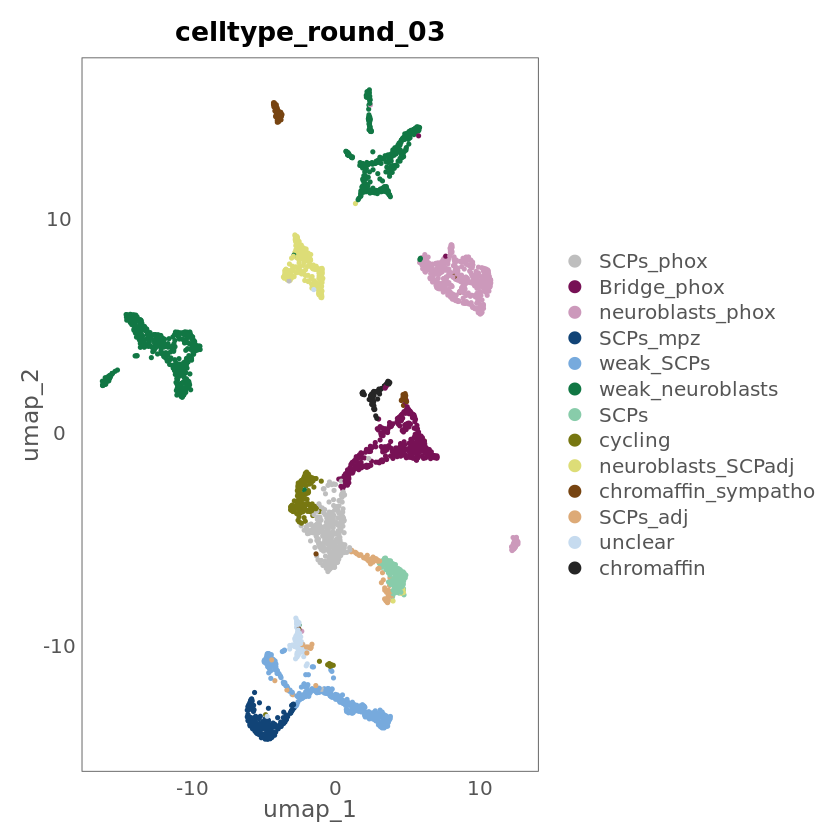

In [89]:
Idents(dat_sub) <- 'seurat_clusters'

dat_sub <- RenameIdents(object = dat_sub,
    '0' = 'SCPs_phox',
    '1' = 'Bridge_phox',
    '2' = 'neuroblasts_phox',
    '3' = 'SCPs_mpz',
    '4' = 'weak_SCPs',
    '5' = 'neuroblasts_phox',
    '6' = 'weak_neuroblasts',
    '7' = 'SCPs',
    '8' = 'cycling',
    '9' = 'neuroblasts_SCPadj',
    '10' = 'weak_neuroblasts',
    '11' = 'weak_neuroblasts',
    '12' = 'Bridge_phox',
    '13' = 'chromaffin_sympatho',
    '14' = 'weak_neuroblasts',
    '15' = 'weak_neuroblasts',
    '16' = 'weak_SCPs',
    '17' = 'SCPs_adj',
    '18' = 'weak_neuroblasts',
    '19' = 'unclear',
    '20' = 'neuroblasts_SCPadj',
    '21' = 'chromaffin',
    '22' = 'weak_SCPs',
    '23' = 'weak_neuroblasts',
    '24' = 'neuroblasts_phox',
    '25' = 'weak_neuroblasts',
    '26' = 'cycling'
)

# save celltype information in the meta.data
dat_sub$celltype_round_03 <- Idents(dat_sub)

# Plot
DimPlot(object = dat_sub, reduction = 'umap', pt.size = 0.8, group.by = "celltype_round_03", cols = c('grey',tol21rainbow[c(1,3,4,6,10,12,13,15,16,18,25,24)]), shuffle = T, raster=FALSE)+
            NoAxes() +
            mytheme_angledYtitle

### 5. subcluster again (round 4)

In [91]:
# reload
dat_sub <- readRDS("daniocell_SAlin_03_clustered.rds")

## subset
dat_name <- "daniocell_SAlin_04"

Idents(dat_sub) <- 'celltype_round_03'
dat_sub <- subset(dat_sub, idents = c('weak_neuroblasts',
                                     'weak_SCPs'),
                            invert = T)

In [92]:
# normalise and scale
dat_sub <- NormalizeData(dat_sub)

all.genes <- rownames(x = dat_sub)
dat_sub <- ScaleData(object = dat_sub, features = all.genes)


Centering and scaling data matrix



In [93]:
# Variable genes

# Load genes associated with the cell cycle that should also be excluded for PCA and clustering
to.regress.cellcycle <- read.csv("zfish_prolif_markers.csv")
to.regress.cellcycle <- as.character(to.regress.cellcycle$x)


dat_sub <- FindVariableFeatures(object = dat_sub,selection.method = 'vst', nfeatures = 2000)
var_feats <- VariableFeatures(object = dat_sub)
var_feats <- var_feats[!var_feats %in% to.regress.cellcycle]

length(var_feats)

[1] 1952

PC_ 1 
Positive:  sncgb, si:dkey-46i9.1, atp1a3b, eno1a, nptna, chga, ndufa4, nefma, zgc:65851, atp1b1b 
	   aldocb, atp2b3b, si:ch73-119p20.1, ndrg3a, snap25b, cplx2l, gapdhs, vamp1, cox6b1, atp1b2a 
	   sst6, tubb2, adam11, ckmt1, XLOC-038060, pygmb, scn8ab, kcna1a, six1b, ckbb 
Negative:  marcksl1b, cd82a, mag, timd4, cldnk, cldn19, si:ch73-335m24.2, qki2, plp1b, zwi 
	   tuba8l3, elovl1b, si:dkey-204f11.64, si:ch211-156j16.1, cd226, tjp2b, tmem125b, mpz, cdhr5a, tlcd1 
	   si:dkey-200l5.4, cd59, ugt8, lim2.2, elovl7a, fabp2, si:dkey-164f24.2, olig2, crip3, si:rp71-19m20.1 
PC_ 2 
Positive:  cldnk, cd59, mbpb, mbpa, mag, plp1b, ppp1r14aa, si:rp71-19m20.1, zwi, si:dkey-164f24.2 
	   cldn19, elovl1b, si:ch73-335m24.2, qki2, fabp2, tlcd1, cdhr5a, tjp2b, cd226, efhd1 
	   timd4, crip3, mpz, slmapb, si:ch211-156j16.1, apoeb, si:dkey-204f11.64, elovl7a, lim2.2, si:dkey-200l5.4 
Negative:  hmga1a, CR812832.1, gap43, hand2, tspan18a, alcama, tubb5, insm1b, tmsb, sox11b 
	   hoxb5b, hoxb5a, 

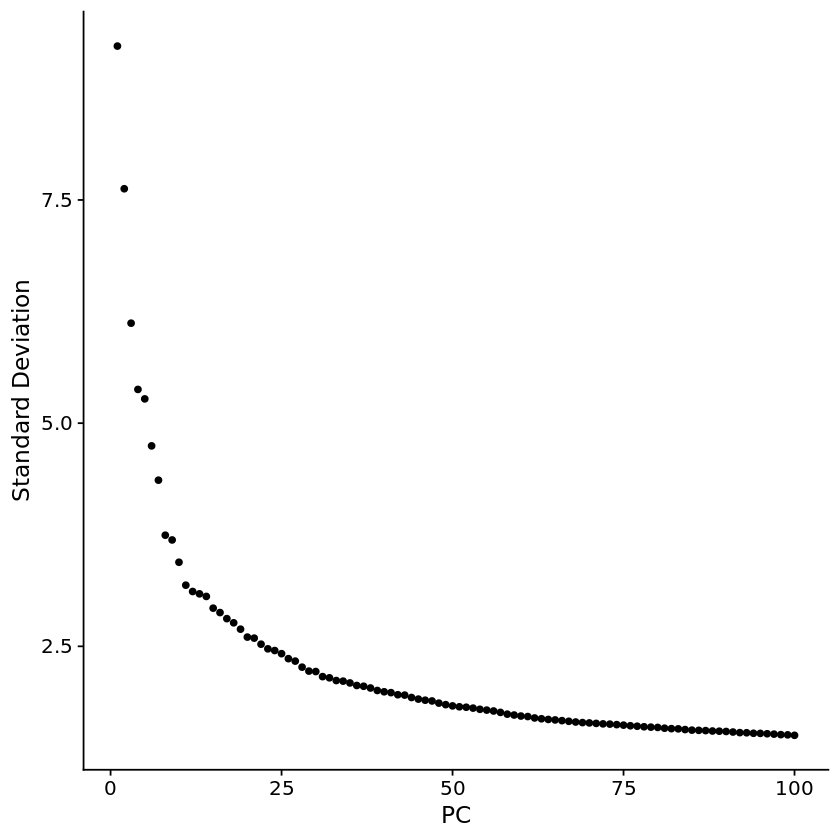

In [94]:
# PCA
dat_sub <- RunPCA(dat_sub, features = var_feats, npcs = 100)

ElbowPlot(object = dat_sub, ndims = 100)

In [95]:
# Cluster and UMAP

# Set number of principal components to use
ndims <- 19

# Clustering
k <- round(max(20,sqrt(ncol(dat_sub)))/4)
if(k %% 2 == 0) {k <- k+1}
if(k > 41) {k <- 41}

dat_sub <- FindNeighbors(object = dat_sub, dims = 1:ndims, k.param = k)
dat_sub <- FindClusters(object = dat_sub, resolution = 1.1)

dat_sub <- RunUMAP(dat_sub, reduction = "pca", dims = 1:ndims)

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 2367
Number of edges: 46396

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8851
Number of communities: 23
Elapsed time: 0 seconds


10:30:10 UMAP embedding parameters a = 0.9922 b = 1.112

Found more than one class "dist" in cache; using the first, from namespace 'spam'

Also defined by ‘BiocGenerics’

10:30:10 Read 2367 rows and found 19 numeric columns

10:30:10 Using Annoy for neighbor search, n_neighbors = 30

Found more than one class "dist" in cache; using the first, from namespace 'spam'

Also defined by ‘BiocGenerics’

10:30:10 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

10:30:10 Writing NN index file to temp file /tmp/RtmpxTi5qa/file3e8b696a2adcf3

10:30:10 Searching Annoy index using 1 thread, search_k = 3000

10:30:10 Annoy recall = 100%

10:30:11 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

10:30:13 Initializing from normalized Laplacian +

#### Plot

##### UMAP

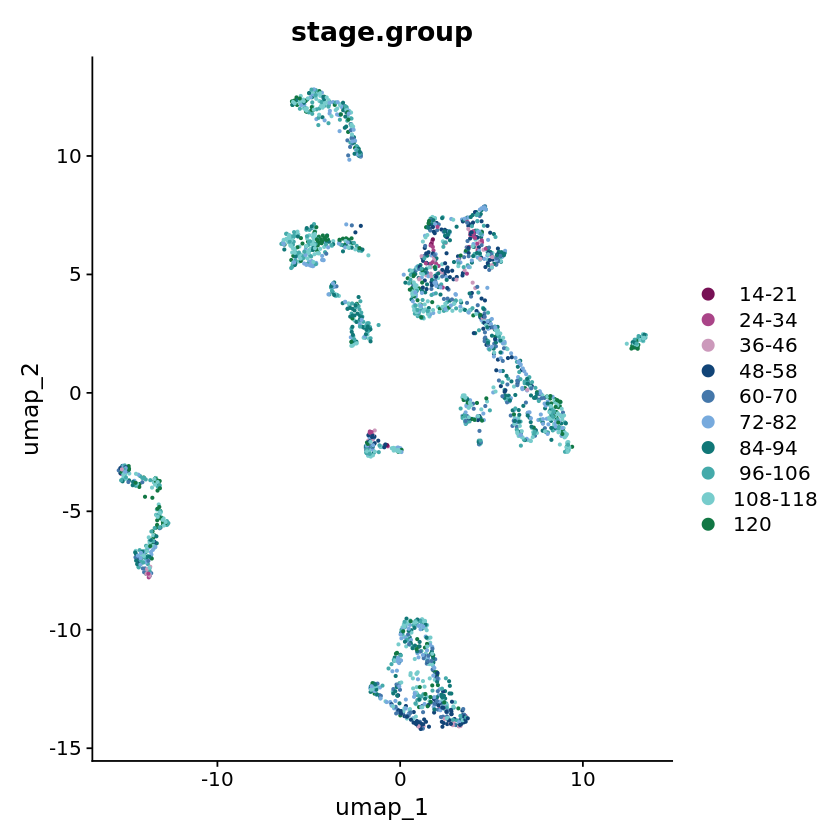

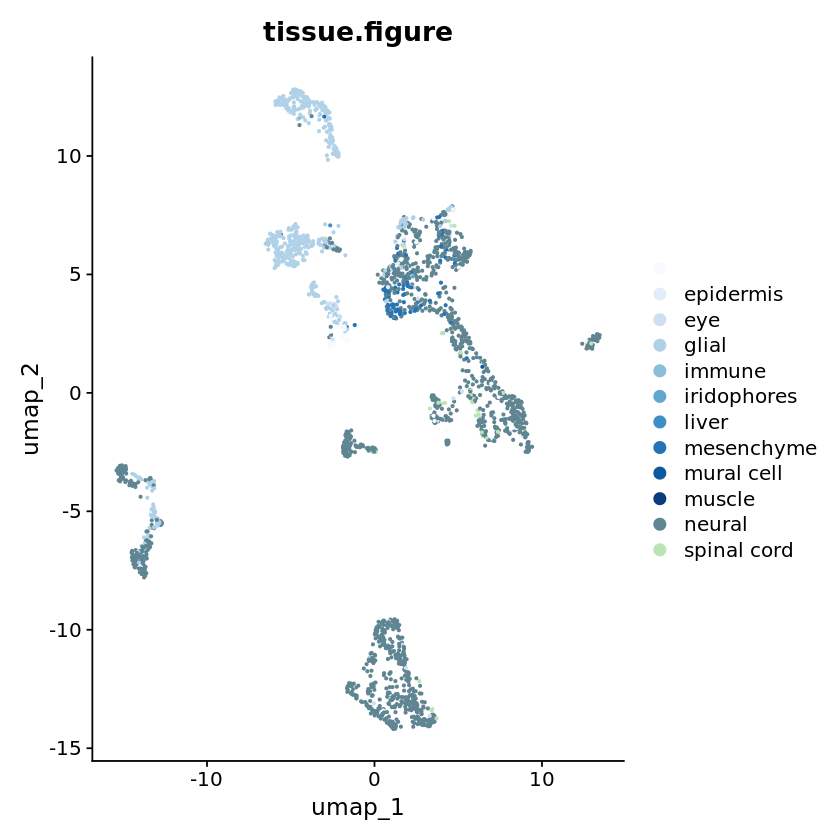

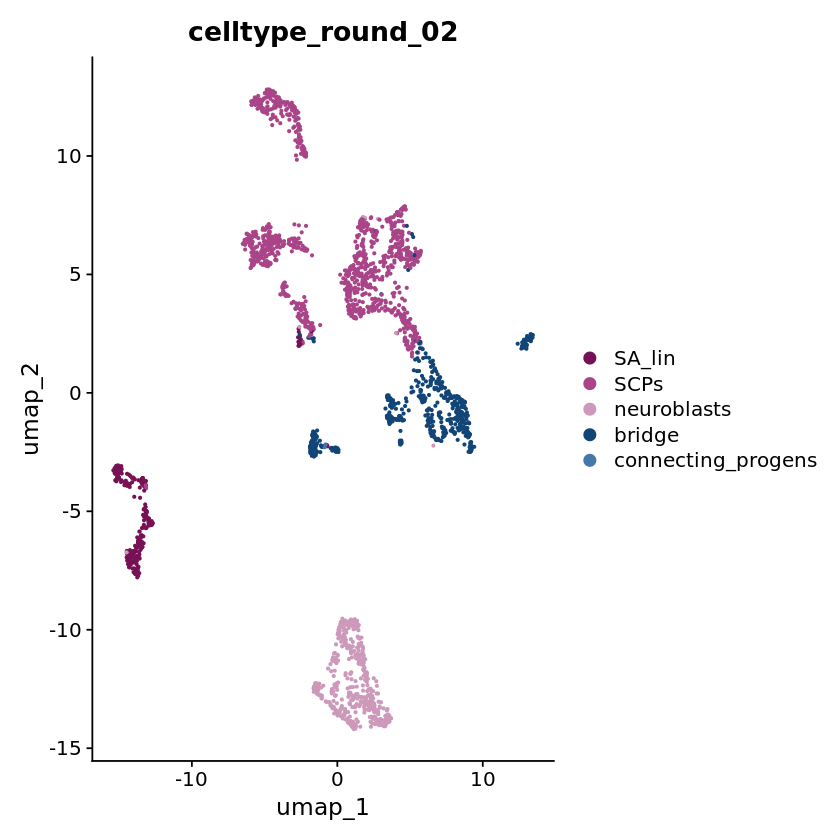

In [96]:
coul <- c(brewer.pal(9, "Blues"),
          brewer.pal(9, "Greens")[3:9],
          brewer.pal(9, "YlOrBr")[1:9],
          brewer.pal(9, "Greys")[1:9]
          )

coul_long <- colorRampPalette(coul)(40)

DimPlot(object = dat_sub, reduction = 'umap', pt.size = 0.5, cols = tol21rainbow, group.by = "stage.group", shuffle = T)

DimPlot(object = dat_sub, reduction = 'umap', pt.size = 0.5, cols = coul_long, group.by = "tissue.figure", shuffle = T)

DimPlot(object = dat_sub, reduction = 'umap', pt.size = 0.5, cols = tol21rainbow, group.by = "celltype_round_02", shuffle = T)


##### symp adrn gene expression

In [97]:
# load published developmental cell type marker gene lists for human fetal adrenal medullary cells from Kildisiute et al., Kameneva et al. and Jansky et al. translated to zebrafish
markers_hum <- read.delim("fetal_adrenal_markers_dr.csv", stringsAsFactors = F, sep = ",", header = T, row.names = NULL)

# convert to list
modules_pan <- as.list(markers_hum)
modules_pan <- lapply(modules_pan, function(X) X[X != ""])
modules_pan <- lapply(modules_pan, function(X) X[X %in% rownames(dat_sub)])

# make sure correct symbols are being used in gene names
modules_pan <- lapply(modules_pan, function(x) gsub("si\\.","si:",x))
modules_pan <- lapply(modules_pan, function(x) gsub("zgc\\.","zgc:",x))
modules_pan <- lapply(modules_pan, function(x) gsub("mt\\.","mt-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("dkey\\.","dkey-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("h211\\.","h211-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("1073\\.","1073-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("1073\\.","1073-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("ch73\\.","ch73-",x))
            
modules_pan <- modules_pan[lengths(modules_pan) >= 3]

In [98]:
# get gene set expression scores
dat <- dat_sub

dat <- AddModuleScore(
  dat,
  features = modules_pan,
  name = names(modules_pan)
)

avexp_test <- as.data.frame(dat@meta.data)

# remove numbers from the module names
colnames(avexp_test) <- gsub('[0-9]+', '', colnames(avexp_test))

Warning message:
“Removed 35 rows containing missing values or values outside the scale range (`geom_point()`).”


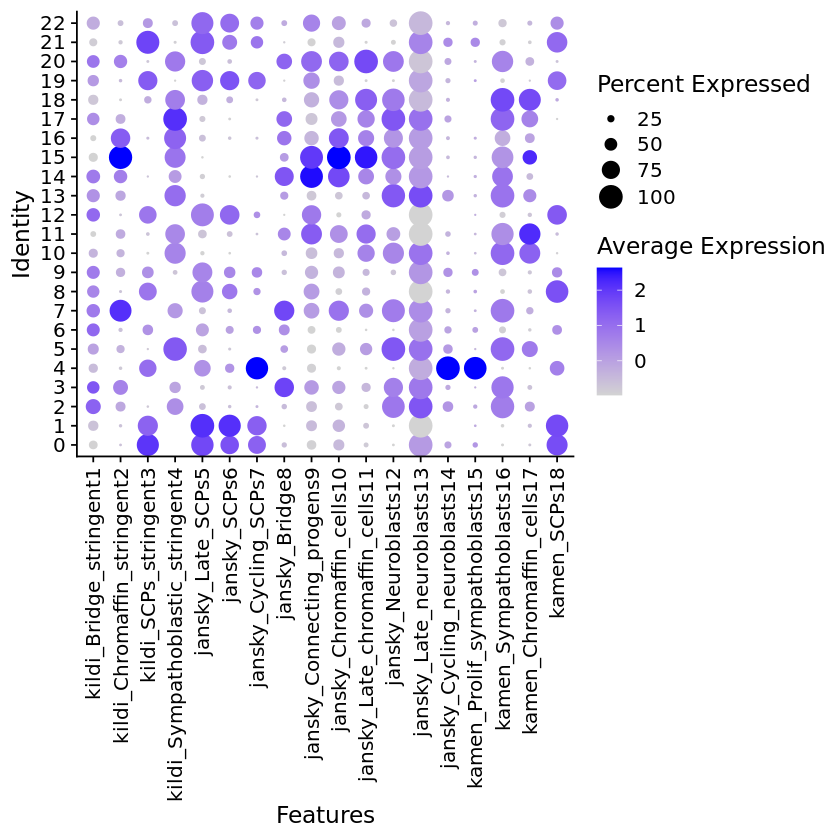

In [99]:
mod_names_numb <- paste0(colnames(markers_hum), c(1: length(colnames(markers_hum))))

DotPlot(dat, features = mod_names_numb, group.by = 'seurat_clusters',
    dot.min = 0.02,
    col.min = min(dat@meta.data[,mod_names_numb]),
    col.max = max(dat@meta.data[,mod_names_numb]))  +
theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1))

##### individual marker genes

Warning message:
“Removed 158 rows containing missing values or values outside the scale range (`geom_point()`).”


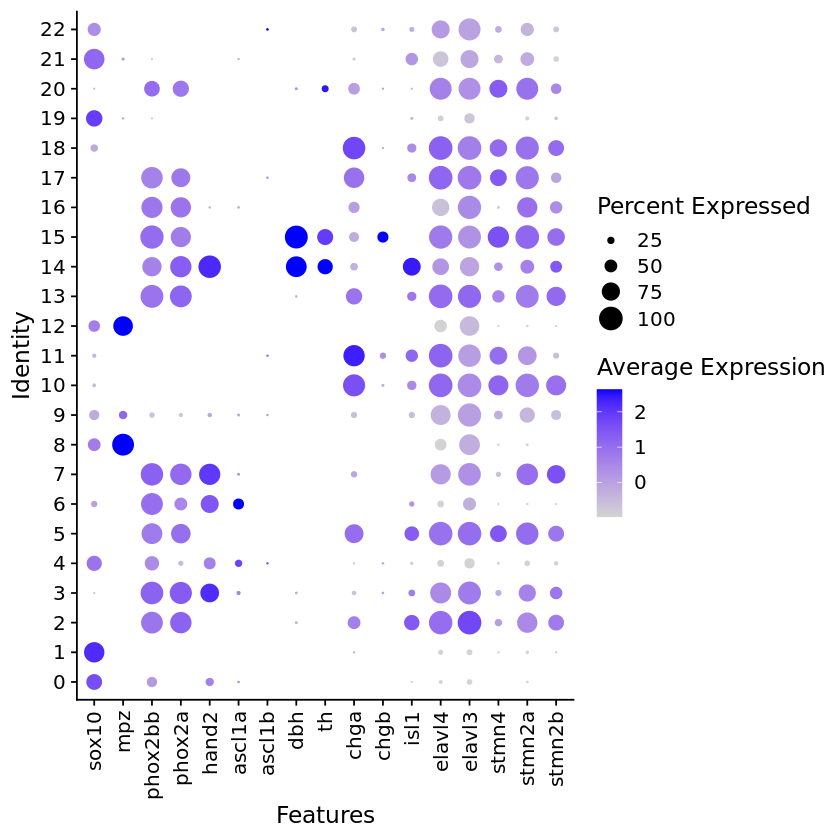

In [100]:
mods_plot <- c('sox10','mpz','phox2bb', 'phox2a','hand2','ascl1a','ascl1b','dbh','th','chga','chgb','isl1','elavl4','elavl3','stmn4','stmn2a','stmn2b')
mods_plot <- mods_plot[mods_plot %in% rownames(dat_sub)]

DotPlot(dat_sub, features = mods_plot, group.by = 'seurat_clusters',
    dot.min = 0.02,
    col.min = min(dat@meta.data[,mod_names_numb]),
    col.max = max(dat@meta.data[,mod_names_numb]))  +
theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1))

#### Find and write out cluster markers

In [ ]:
Idents(dat_sub)<- "seurat_clusters"

# plot markers:
markers_all <- FindAllMarkers(object = dat_sub, only.pos = TRUE, min.pct = 0.5, logfc.threshold = 0.8)

# Then print
write.csv(markers_all, file = paste0("clusterMarkersAll_",dat_name,"_seurclusts_minpct50_logfct_80.csv"))

#### assign symp adrn dev cell types

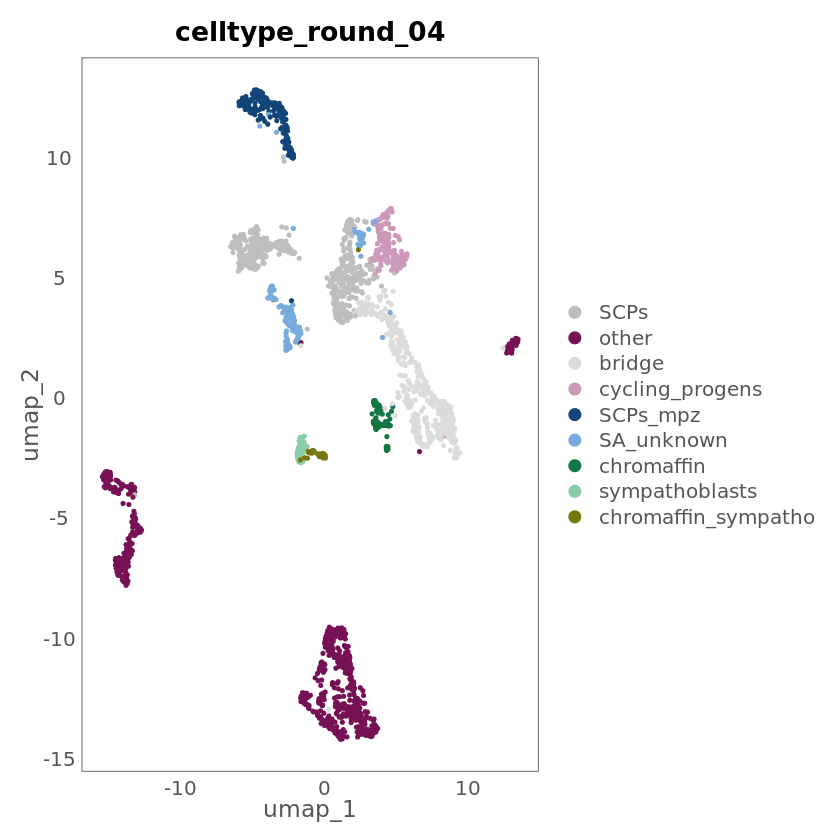

In [101]:
Idents(dat_sub) <- 'seurat_clusters'

dat_sub <- RenameIdents(object = dat_sub,
'0' = 'SCPs',
'1' = 'SCPs',
'2' = 'other',
'3' = 'bridge',
'4' = 'cycling_progens',
'5' = 'other',
'6' = 'bridge',
'7' = 'bridge',
'8' = 'SCPs_mpz',
'9' = 'SA_unknown',
'10' = 'other',
'11' = 'other',
'12' = 'SCPs_mpz',
'13' = 'other',
'14' = 'chromaffin',
'15' = 'sympathoblasts',
'16' = 'other',
'17' = 'other',
'18' = 'other',
'19' = 'SCPs',
'20' = 'chromaffin_sympatho',
'21' = 'SCPs',
'22' = 'SA_unknown'
)

# save celltype information in the meta.data
dat_sub$celltype_round_04 <- Idents(dat_sub)


# Plot
DimPlot(object = dat_sub, reduction = 'umap', pt.size = 0.8, group.by = "celltype_round_04",
        cols = c('grey',tol21rainbow[c(1,28,3,4,6,10,12,13,15,16,18)]), shuffle = T, raster=FALSE) +
            NoAxes() +
            mytheme_angledYtitle

In [103]:
# save object
saveRDS(dat_sub, paste0(dat_name,"_clustered.rds"))

### 6. subcluster again (round 5)

In [202]:
#reload
dat_sub <- readRDS("daniocell_SAlin_04_clustered.rds")

In [203]:
# subset
dat_name <- "daniocell_SAlin_sub_05"

Idents(dat_sub) <- 'celltype_round_04'
dat_sub <- subset(dat_sub, idents = c('other'),
                            invert = T)

dim(dat_sub)

[1] 30910  1624

In [204]:
# normalise and scale
dat_sub <- NormalizeData(dat_sub)

all.genes <- rownames(x = dat_sub)
dat_sub <- ScaleData(object = dat_sub, features = all.genes)


Centering and scaling data matrix



In [205]:
# Variable genes

# Load genes associated with the cell cycle that should also be excluded for PCA and clustering
to.regress.cellcycle <- read.csv("zfish_prolif_markers.csv")
to.regress.cellcycle <- as.character(to.regress.cellcycle$x)


dat_sub <- FindVariableFeatures(object = dat_sub,selection.method = 'vst', nfeatures = 2000)
var_feats <- VariableFeatures(object = dat_sub)
var_feats <- var_feats[!var_feats %in% to.regress.cellcycle]

length(var_feats)

[1] 1951

PC_ 1 
Positive:  cldnk, zwi, cd59, qki2, mag, cldn19, si:rp71-19m20.1, mbpa, mbpb, elovl1b 
	   timd4, fabp2, plp1b, cdhr5a, si:dkey-164f24.2, tjp2b, tlcd1, si:ch211-156j16.1, si:ch73-335m24.2, ppp1r14aa 
	   si:dkey-204f11.64, cd226, tmem125b, lim2.2, efhd1, mpz, crip3, elovl7a, apoeb, si:dkey-200l5.4 
Negative:  stmn2a, gap43, sncb, tuba1c, ywhag2, zgc:65894, scg2b, atp6v0cb, rtn1b, uchl1 
	   cplx2, syt1a, tmsb2, stxbp1a, atp2b3a, maptb, calm1b, stx1b, gapdhs, tuba1a 
	   tubb5, phox2a, snap25a, tmsb, eno1a, elavl4, stmn2b, slc35g2a, id4, olfm1b 
PC_ 2 
Positive:  foxd3, pmp22a, her6, hmga1a, id1, ly6m5, scn4ab, fabp7a, her15.1, krt8 
	   rgcc, foxp4, XLOC-003690, her9, mdka, tuba8l, nutf2l, dut, socs3b, chaf1a 
	   ccna2, mad2l1, hmga2, gfra1b, mcm7, npm1a, zgc:165555.3, cdca5, si:ch211-156b7.4, cpn1 
Negative:  si:ch73-335m24.2, plp1b, cd226, mpz, crip3, cldnk, si:dkey-200l5.4, mag, dpysl5a, cd9b 
	   slmapb, LOC100333482, mid1ip1b, cd59, apoeb, hmgn3, BX000438.1, zgc:153981, elo

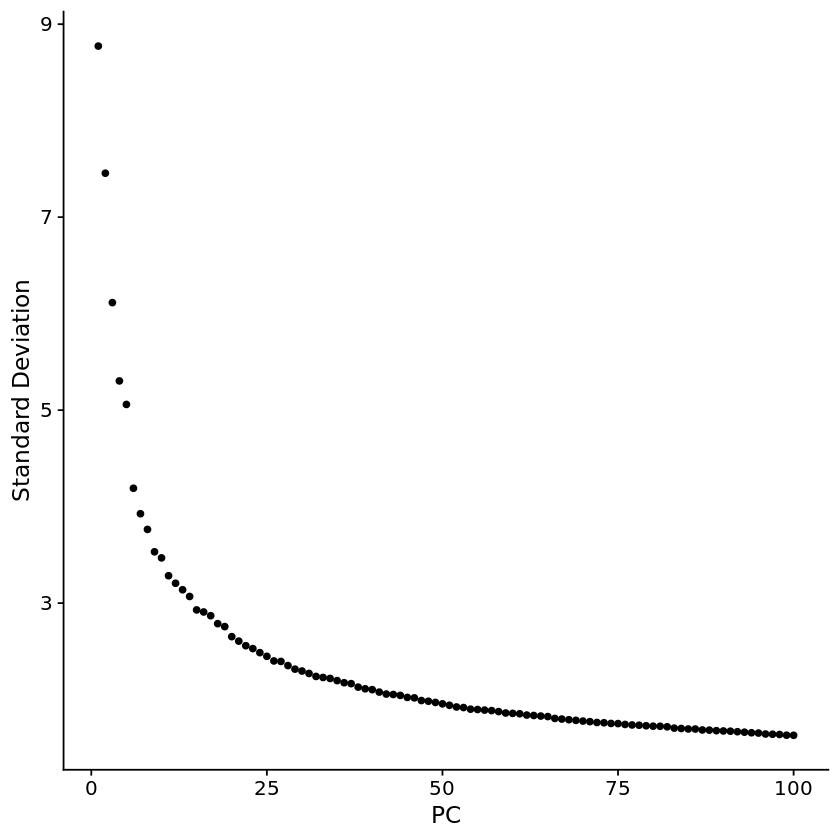

In [206]:
# PCA
dat_sub <- RunPCA(dat_sub, features = var_feats, npcs = 100)

ElbowPlot(object = dat_sub, ndims = 100)

In [207]:
# Cluster and UMAP

# Set number of principal components to use
ndims <- 14

# Clustering
k <- round(max(20,sqrt(ncol(dat_sub)))/4)
if(k %% 2 == 0) {k <- k+1}
if(k > 41) {k <- 41}

dat_sub <- FindNeighbors(object = dat_sub, dims = 1:ndims, k.param = k)
dat_sub <- FindClusters(object = dat_sub, resolution = 1.8) # NOTE that I used high clustering resolution here

dat_sub <- RunUMAP(dat_sub, reduction = "pca", dims = 1:ndims)

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 1624
Number of edges: 23781

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8227
Number of communities: 28
Elapsed time: 0 seconds


11:33:01 UMAP embedding parameters a = 0.9922 b = 1.112

Found more than one class "dist" in cache; using the first, from namespace 'spam'

Also defined by ‘BiocGenerics’

11:33:01 Read 1624 rows and found 14 numeric columns

11:33:01 Using Annoy for neighbor search, n_neighbors = 30

Found more than one class "dist" in cache; using the first, from namespace 'spam'

Also defined by ‘BiocGenerics’

11:33:01 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

11:33:01 Writing NN index file to temp file /tmp/RtmpxTi5qa/file3e8b694c93a13e

11:33:01 Searching Annoy index using 1 thread, search_k = 3000

11:33:01 Annoy recall = 100%

11:33:02 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

11:33:04 Initializing from normalized Laplacian +

#### Plot

##### UMAP

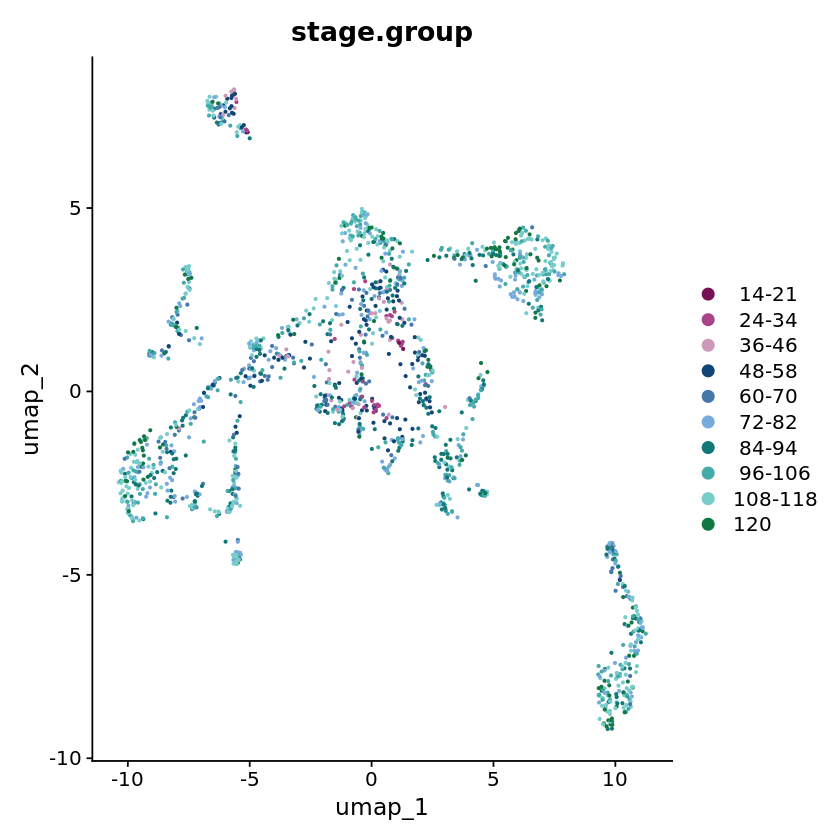

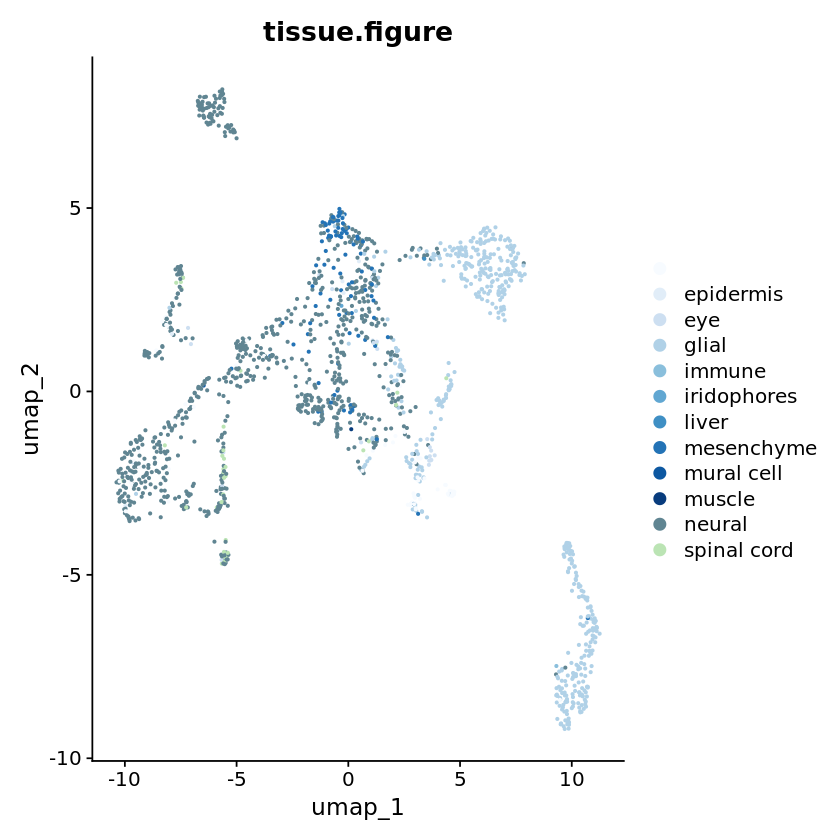

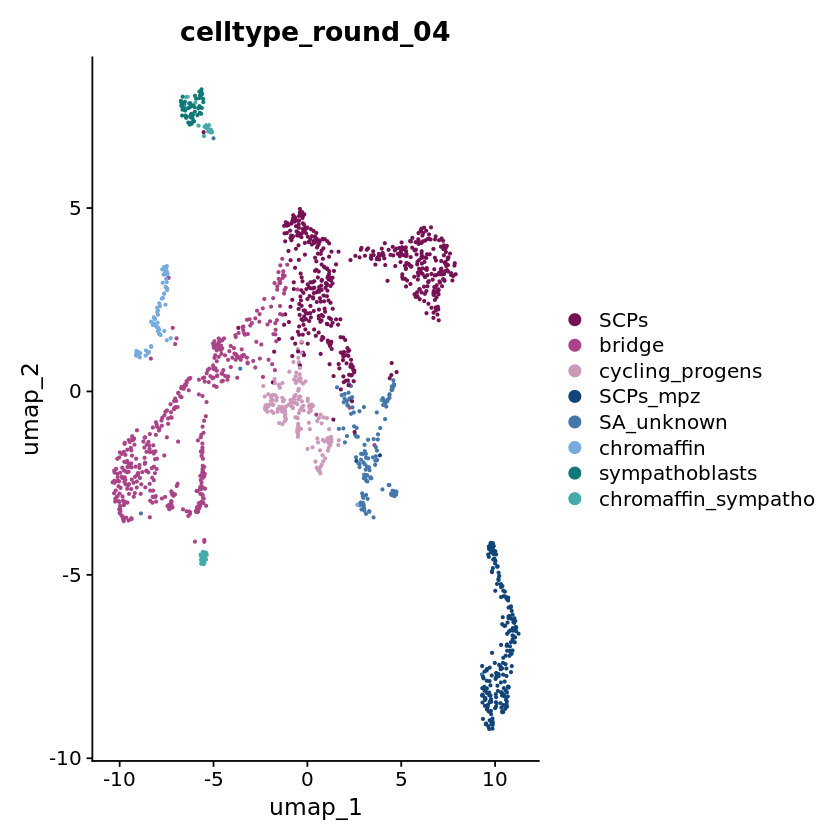

In [208]:
coul <- c(brewer.pal(9, "Blues"),
          brewer.pal(9, "Greens")[3:9],
          brewer.pal(9, "YlOrBr")[1:9],
          brewer.pal(9, "Greys")[1:9]
          )

coul_long <- colorRampPalette(coul)(40)

DimPlot(object = dat_sub, reduction = 'umap', pt.size = 0.5, cols = tol21rainbow, group.by = "stage.group", shuffle = T)

DimPlot(object = dat_sub, reduction = 'umap', pt.size = 0.5, cols = coul_long, group.by = "tissue.figure", shuffle = T)

DimPlot(object = dat_sub, reduction = 'umap', pt.size = 0.5, cols = tol21rainbow, group.by = "celltype_round_04", shuffle = T)


##### symp adrn gene expression

In [209]:
# load published developmental cell type marker gene lists for human fetal adrenal medullary cells from Kildisiute et al., Kameneva et al. and Jansky et al. translated to zebrafish
markers_hum <- read.delim("fetal_adrenal_markers_dr.csv", stringsAsFactors = F, sep = ",", header = T, row.names = NULL)

# convert to list
modules_pan <- as.list(markers_hum)
modules_pan <- lapply(modules_pan, function(X) X[X != ""])
modules_pan <- lapply(modules_pan, function(X) X[X %in% rownames(dat_sub)])

# make sure correct symbols are being used in gene names
modules_pan <- lapply(modules_pan, function(x) gsub("si\\.","si:",x))
modules_pan <- lapply(modules_pan, function(x) gsub("zgc\\.","zgc:",x))
modules_pan <- lapply(modules_pan, function(x) gsub("mt\\.","mt-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("dkey\\.","dkey-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("h211\\.","h211-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("1073\\.","1073-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("1073\\.","1073-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("ch73\\.","ch73-",x))
            
modules_pan <- modules_pan[lengths(modules_pan) >= 3]

In [210]:
# get gene set expression scores
dat <- dat_sub

dat <- AddModuleScore(
  dat,
  features = modules_pan,
  name = names(modules_pan)
)

avexp_test <- as.data.frame(dat@meta.data)

# remove numbers from the module names
colnames(avexp_test) <- gsub('[0-9]+', '', colnames(avexp_test))

Warning message:
“Removed 22 rows containing missing values or values outside the scale range (`geom_point()`).”


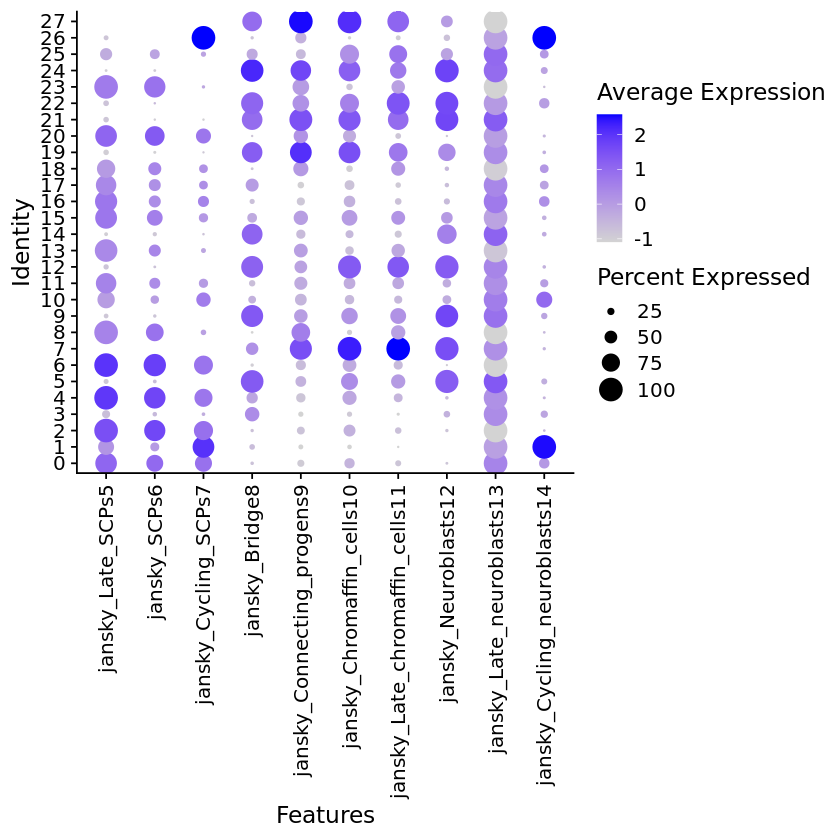

In [211]:
mod_names_numb <- paste0(colnames(markers_hum), c(1: length(colnames(markers_hum))))

DotPlot(dat, features = mod_names_numb[mod_names_numb %like any% 'jansky%'], group.by = 'seurat_clusters',
    dot.min = 0.02,
    col.min = min(dat@meta.data[,mod_names_numb]),
    col.max = max(dat@meta.data[,mod_names_numb]))  +
theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1))

##### individual marker genes

Warning message:
“Removed 200 rows containing missing values or values outside the scale range (`geom_point()`).”
Warning message:
“Removed 144 rows containing missing values or values outside the scale range (`geom_point()`).”


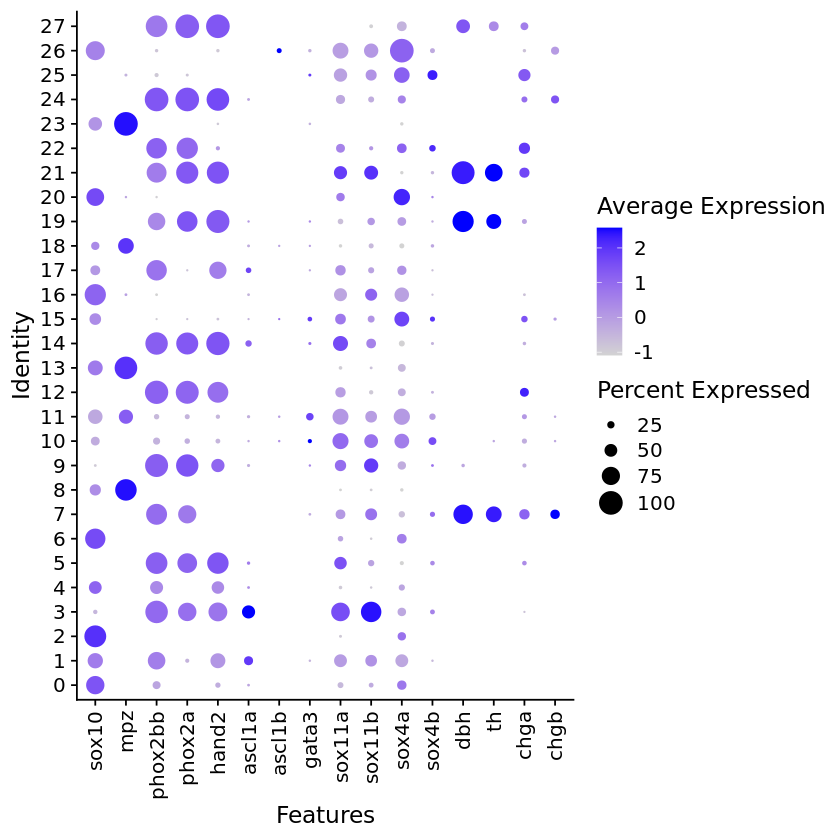

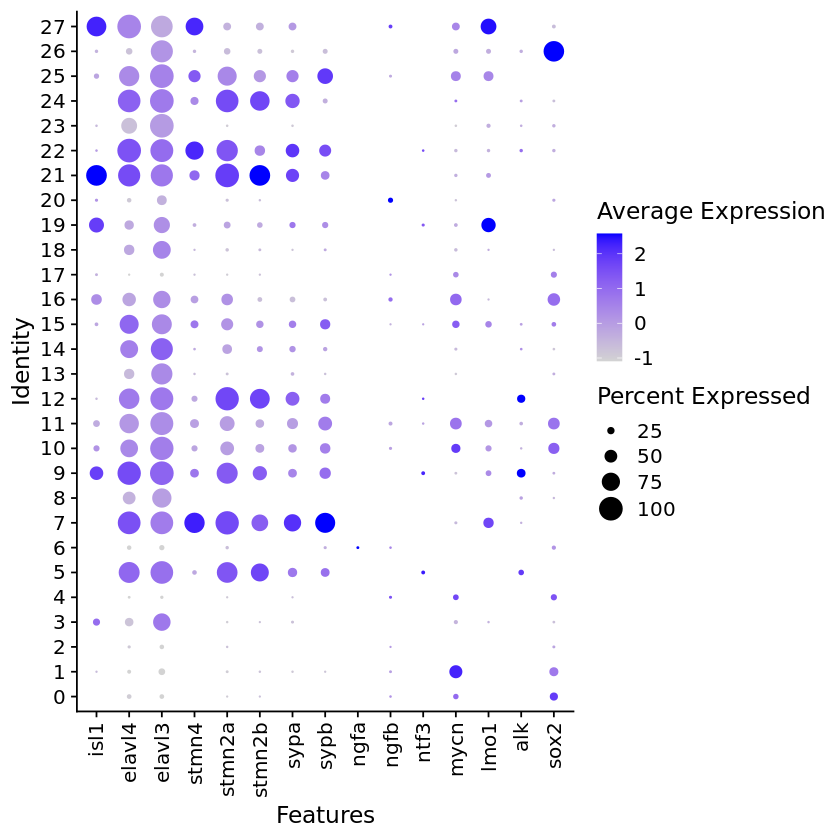

In [212]:
mods_plot <- c('sox10','mpz','phox2bb', 'phox2a','hand2','ascl1a','ascl1b','gata3','sox11a','sox11b','sox4a','sox4b','dbh','th','chga','chgb')
mods_plot <- mods_plot[mods_plot %in% rownames(dat_sub)]

DotPlot(dat_sub, features = mods_plot, group.by = 'seurat_clusters',
    dot.min = 0.02,
    col.min = min(dat@meta.data[,mod_names_numb]),
    col.max = max(dat@meta.data[,mod_names_numb]))  +
theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1))

mods_plot <- c('isl1','elavl4','elavl3','stmn4','stmn2a','stmn2b','sypa','sypb','ngfa','ngfb','ntf3','mycn','lmo1','alk','sox2')
mods_plot <- mods_plot[mods_plot %in% rownames(dat_sub)]

DotPlot(dat_sub, features = mods_plot, group.by = 'seurat_clusters',
    dot.min = 0.02,
    col.min = min(dat@meta.data[,mod_names_numb]),
    col.max = max(dat@meta.data[,mod_names_numb]))  +
theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1))


#### Find and write out cluster markers

In [135]:
Idents(dat_sub)<- "seurat_clusters"

# plot markers:
markers_all <- FindAllMarkers(object = dat_sub, only.pos = TRUE, min.pct = 0.5, logfc.threshold = 0.8)

# Then print
write.csv(markers_all, file = paste0("clusterMarkersAll_",dat_name,"_seurclusts_minpct50_logfct_80.csv"))

Calculating cluster 0

For a (much!) faster implementation of the Wilcoxon Rank Sum Test,
(default method for FindMarkers) please install the presto package
--------------------------------------------
install.packages('devtools')
devtools::install_github('immunogenomics/presto')
--------------------------------------------
After installation of presto, Seurat will automatically use the more 
efficient implementation (no further action necessary).
This message will be shown once per session

Calculating cluster 1

Calculating cluster 2

Calculating cluster 3

Calculating cluster 4

Calculating cluster 5

Calculating cluster 6

Calculating cluster 7

Calculating cluster 8

Calculating cluster 9

Calculating cluster 10

Calculating cluster 11

Calculating cluster 12

Calculating cluster 13

Calculating cluster 14

Calculating cluster 15

Calculating cluster 16

Calculating cluster 17

Calculating cluster 18

Calculating cluster 19

Calculating cluster 20

Calculating cluster 21

Calculat

#### assign symp adrn dev cell types

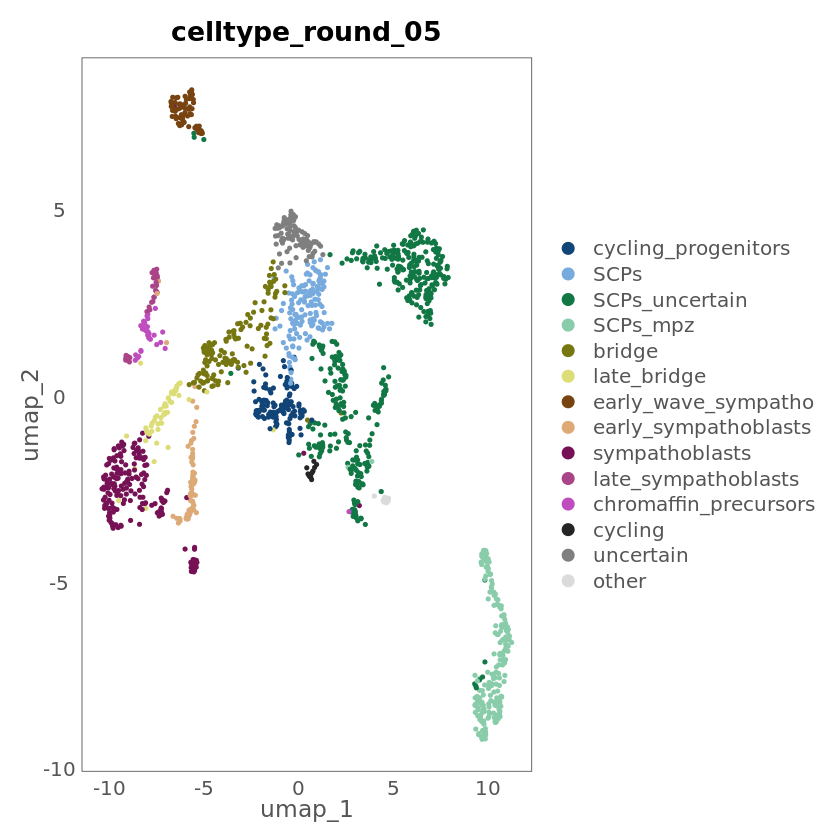

In [213]:
Idents(dat_sub) <- 'seurat_clusters'

dat_sub <- RenameIdents(object = dat_sub,
    '0' = 'SCPs',
    '1' = 'cycling_progenitors',
    '2' = 'SCPs_uncertain',
    '3' = 'bridge',
    '4' = 'uncertain',
    '5' = 'sympathoblasts',
    '6' = 'SCPs_uncertain',
    '7' = 'early_wave_sympatho',
    '8' = 'SCPs_mpz',
    '9' = 'early_sympathoblasts',
    '10' = 'SCPs_uncertain',
    '11' = 'SCPs_uncertain',
    '12' = 'sympathoblasts',
    '13' = 'SCPs_mpz',
    '14' = 'late_bridge',
    '15' = 'SCPs_uncertain',
    '16' = 'SCPs_uncertain',
    '17' = 'bridge',
    '18' = 'SCPs_mpz',
    '19' = 'chromaffin_precursors',
    '20' = 'SCPs_uncertain',
    '21' = 'late_sympathoblasts',
    '22' = 'sympathoblasts',
    '23' = 'SCPs_mpz',
    '24' = 'sympathoblasts',
    '25' = 'other',
    '26' = 'cycling',
    '27' = 'late_sympathoblasts'
)

# save celltype information in the meta.data (in the column "celltype""
dat_sub$celltype_round_05 <- Idents(dat_sub)

dat_sub$celltype_round_05 <- factor(as.character(dat_sub$celltype_round_05),
                                    levels = c( 'cycling_progenitors',
                                                'SCPs',
                                                'SCPs_uncertain',
                                                'SCPs_mpz',
                                                'bridge',
                                                'late_bridge',
                                                'early_wave_sympatho',
                                                'early_sympathoblasts',
                                                'sympathoblasts',
                                                'late_sympathoblasts',
                                                'chromaffin_precursors',
                                                'cycling',
                                                'uncertain',
                                                'other'
                                             )
                                    )

# Plot
DimPlot(object = dat_sub, reduction = 'umap', pt.size = 0.8, group.by = "celltype_round_05",
        cols = c(tol21rainbow[c(4,6,10,12,13,15,16,18,1,2,32,24,34,28)]), shuffle = T, raster=FALSE) +
            NoAxes() +
            mytheme_angledYtitle

In [214]:
# save object
saveRDS(dat_sub, paste0(dat_name,"_clustered.rds"))

### 7. Transfer assigned cell types back to entire starting cell population
Check whether the cells extracted also clustered together initially.

In [215]:
# save cell type assignments
ct_assign_SA_lin <- dat_sub@meta.data
ct_assign_SA_lin$celltype_SA_lin <- ct_assign_SA_lin$celltype_round_05
ct_assign_SA_lin$cell_bc <- rownames(ct_assign_SA_lin)
ct_assign_SA_lin <- ct_assign_SA_lin[,c('cell_bc','celltype_SA_lin')]

write.csv(ct_assign_SA_lin, file = paste0("ctAssignments_SA_lineage_",dat_name,".csv"), quote = F)


In [216]:
ct_assign_SA_lin <- read.delim("ctAssignments_SA_lineage_daniocell_SAlin_sub_05.csv", sep = ',', stringsAsFactors = F, row.names = 1)


In [217]:
# reload dataset only subset for cells with expression of at least one marker gene (step 1)
dat_name <- "daniocell_SAlin"

dat_sub <- readRDS("daniocell_SAlin_clustered.Robj")

In [218]:
# add cell type assignments
metadata <- dat_sub@meta.data
metadata$cell_bc <- rownames(metadata)

metadata_ext <- left_join(metadata, ct_assign_SA_lin, by = 'cell_bc')
rownames(metadata_ext) <- metadata_ext$cell_bc

# add extended metadata to seurat object
if(FALSE %in% names(table(rownames(metadata_ext) == rownames(dat_sub@meta.data)))){
    print('cell barcodes in seurat object and metadata do not match - metadata could not be added to seurat object')
}else{
    dat_sub@meta.data <- metadata_ext
}

#### Plot cells with assigned cell types within large dataset

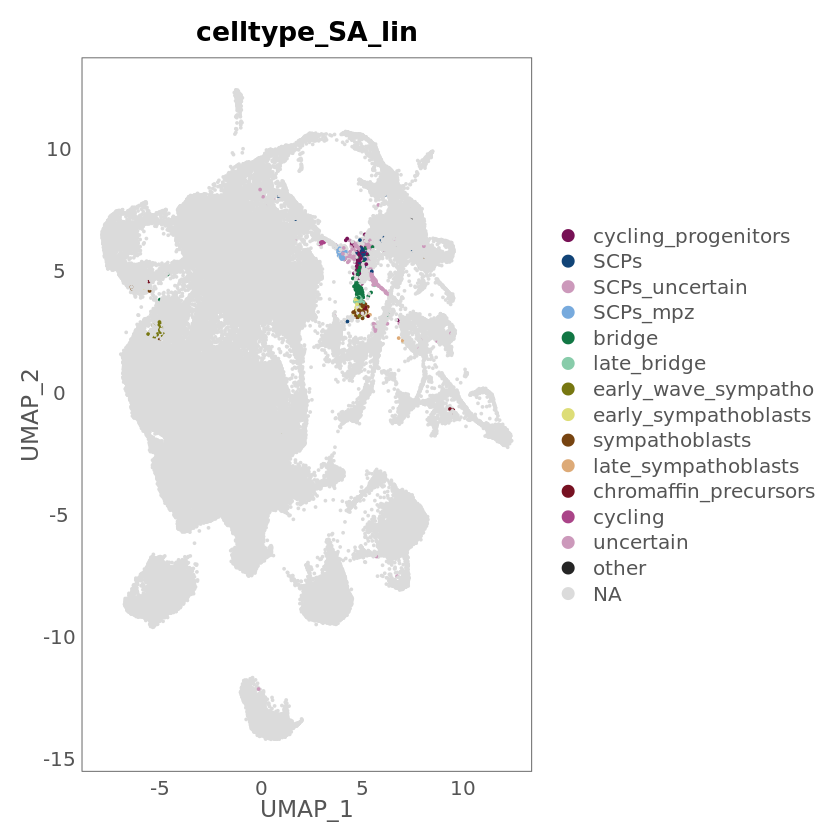

In [219]:
dat_sub$celltype_SA_lin <- factor(as.character(dat_sub$celltype_SA_lin),
                                    levels = c( 'cycling_progenitors',
                                                'SCPs',
                                                'SCPs_uncertain',
                                                'SCPs_mpz',
                                                'bridge',
                                                'late_bridge',
                                                'early_wave_sympatho',
                                                'early_sympathoblasts',
                                                'sympathoblasts',
                                                'late_sympathoblasts',
                                                'chromaffin_precursors',
                                                'cycling',
                                                'uncertain',
                                                'other',
                                                NA
                                    ))

# Plot
DimPlot(object = dat_sub, reduction = 'umap', pt.size = 0.4, group.by = "celltype_SA_lin", na.value = tol21rainbow[28],
        cols = tol21rainbow[c(1,4,3,6,10,12,13,15,16,18,19,2,3,24)], shuffle = T, raster=FALSE) +
            NoAxes() +
            mytheme_angledYtitle

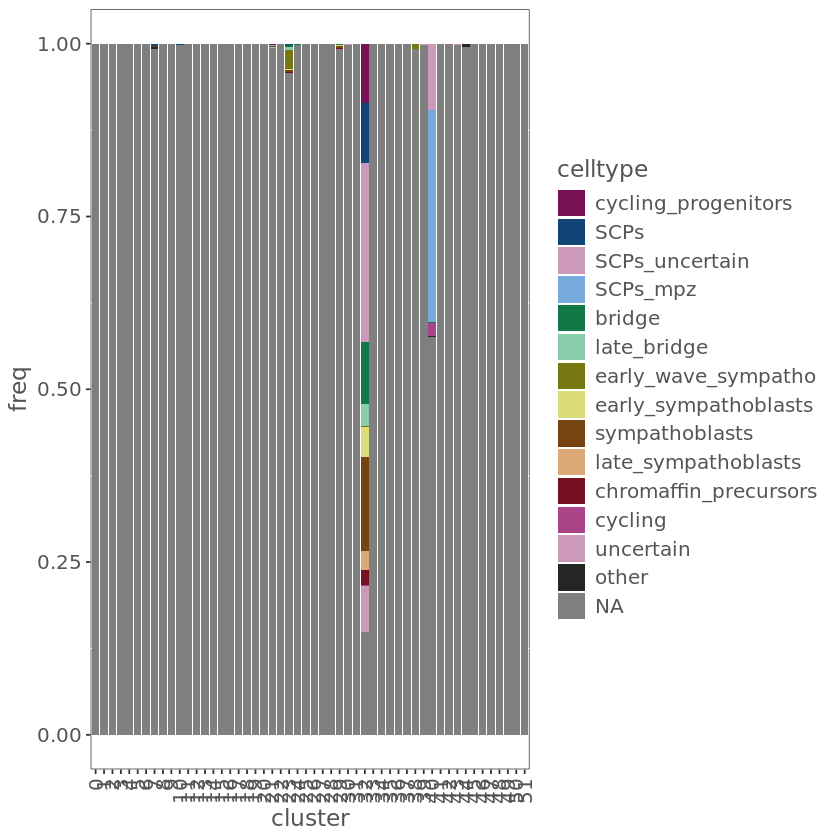

In [220]:
# Check fraction of clusters assigned to CT
dat_sub$celltype_SA_lin_noNA <- as.character(dat_sub$celltype_SA_lin)
dat_sub$celltype_SA_lin_noNA[is.na(dat_sub$celltype_SA_lin_noNA)] <- 'NA'


# get frequency tables
clus_freqs <- as.data.frame(table(dat_sub$celltype_SA_lin_noNA, dat_sub$seurat_clusters))
colnames(clus_freqs) <- c('celltype','cluster','freq')


clus_freqs$celltype <- factor(as.character(clus_freqs$celltype),
                                    levels = c('cycling_progenitors',
                                                'SCPs',
                                                'SCPs_uncertain',
                                                'SCPs_mpz',
                                                'bridge',
                                                'late_bridge',
                                                'early_wave_sympatho',
                                                'early_sympathoblasts',
                                                'sympathoblasts',
                                                'late_sympathoblasts',
                                                'chromaffin_precursors',
                                                'cycling',
                                                'uncertain',
                                                'other',
                                                NA
                                             )
                                    )

# Stacked + percent
ggplot(clus_freqs, aes(fill=celltype, y=freq, x=cluster)) + 
    geom_bar(position="fill", stat="identity") +
    scale_fill_manual(values = tol21rainbow[c(1,4,3,6,10,12,13,15,16,18,19,2,3,24,28)]) +
    mytheme_angledX

Conclusion: Most annotated cells are found within few initial cluster. While this is only a measure of transcriptomic similarity, it indicates that they may represent a group of closely related differentiating cell states.

### 8. FINAL extraction and plotting

In [221]:
# reload object
dat_sub <- readRDS("daniocell_SAlin_sub_05_clustered.rds")

In [222]:
dat_name <- "daniocell_SAlin_sub_cellrank"

# subset
Idents(dat_sub) <- 'celltype_round_05'
dat_sub <- subset(dat_sub, idents = c('SCPs_uncertain','SCPs_mpz','early_wave_sympatho','cycling','other'), invert = T)

In [223]:
# Normalise and scale
dat_sub <- NormalizeData(dat_sub)

all.genes <- rownames(x = dat_sub)
dat_sub <- ScaleData(object = dat_sub, features = all.genes)


Centering and scaling data matrix



In [224]:
# Variable genes

# Load genes associated with the cell cycle that should also be excluded for PCA and clustering
to.regress.cellcycle <- read.csv("zfish_prolif_markers.csv")
to.regress.cellcycle <- as.character(to.regress.cellcycle$x)


dat_sub <- FindVariableFeatures(object = dat_sub,selection.method = 'vst', nfeatures = 2000)
var_feats <- VariableFeatures(object = dat_sub)
var_feats <- var_feats[!var_feats %in% to.regress.cellcycle]

length(var_feats)

[1] 1935

PC_ 1 
Positive:  foxd3, fabp7a, pmp22a, qkia, her6, id1, krt8, marcksl1a, sox10, tuba8l 
	   phlda2, zeb2a, scn4ab, XLOC-003690, foxp4, krt18b, rgcc, rpl23a, si:ch211-137a8.4, ly6m5 
	   dut, ahcy, nutf2l, her9, sb:cb81, tuba8l3, her15.1, hmga2, fabp3, hmga1a 
Negative:  stmn2a, gng3, gap43, zgc:65894, gapdhs, syt1a, sncb, rtn1b, cplx2, mllt11 
	   elavl4, ywhag2, uchl1, islr2, rab6bb, atp2b3a, elavl3, tuba1c, scg2b, cpe 
	   stx1b, calm1b, stmn2b, vipb, tmsb2, maptb, gng2, prph, olfm1b, vat1 
PC_ 2 
Positive:  rgs5a, phex, dbh, epas1b, ca2, epas1a, th, si:dkey-85n7.8, lmo1, dgkzb 
	   rgs4, C12orf75, kcnk9, her5, slc18a2, ndufa4l2a, ankrd63, isl1, atp1a3b, rprma 
	   tbx20, si:ch211-67e16.11, tph1a, gyg1a, il7r, insm1a, zgc:110699, ism1, INSM2, GPR139 
Negative:  tspan18a, etv1, vipb, nos1, sult6b1, hoxb5b, adcyap1b, tbx3a, si:ch211-207d6.2, meis1b 
	   si:ch211-214p16.2, atp11a, si:dkeyp-66d1.7, dgkaa, CABZ01043955.1, ebf1a, si:ch73-46j18.5, kif26aa, syt14a, si:dkeyp-120h9.1 
	   at

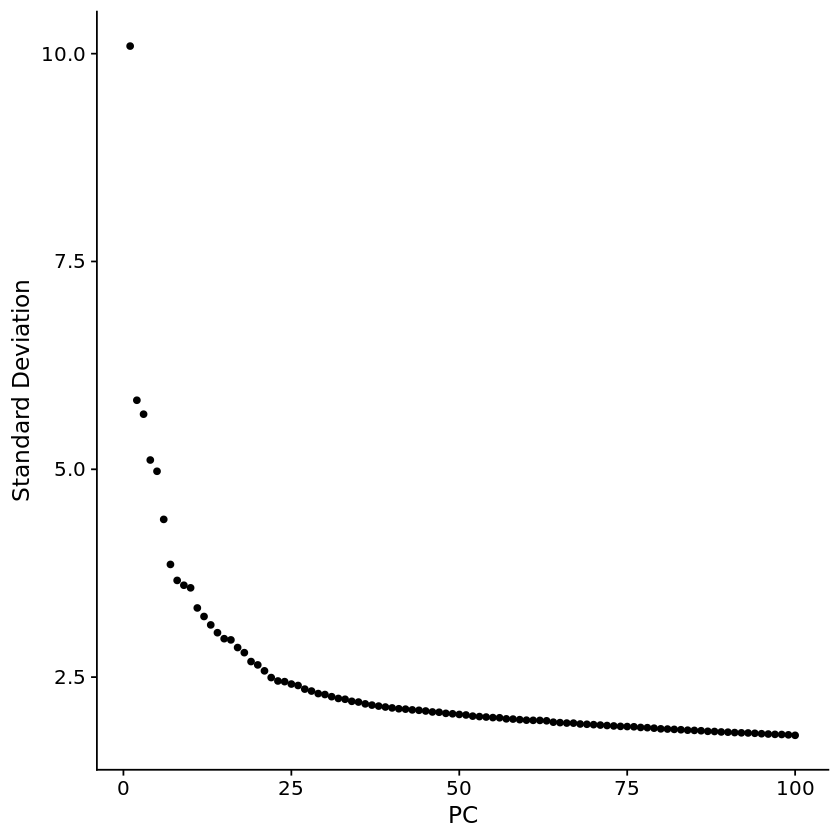

In [225]:
# PCA
dat_sub <- RunPCA(dat_sub, features = var_feats, npcs = 100)

ElbowPlot(object = dat_sub, ndims = 100)

In [226]:
# Cluster and UMAP

# Set number of principal components to use
ndims <- 14

# Clustering
k <- round(max(20,sqrt(ncol(dat_sub)))/4)
if(k %% 2 == 0) {k <- k+1}
if(k > 41) {k <- 41}

dat_sub <- FindNeighbors(object = dat_sub, dims = 1:ndims, k.param = k)
dat_sub <- FindClusters(object = dat_sub, resolution = 1.1)

dat_sub <- RunUMAP(dat_sub, reduction = "pca", dims = 1:ndims)

Computing nearest neighbor graph

Computing SNN



Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 884
Number of edges: 10451

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8249
Number of communities: 21
Elapsed time: 0 seconds


11:42:28 UMAP embedding parameters a = 0.9922 b = 1.112

Found more than one class "dist" in cache; using the first, from namespace 'spam'

Also defined by ‘BiocGenerics’

11:42:28 Read 884 rows and found 14 numeric columns

11:42:28 Using Annoy for neighbor search, n_neighbors = 30

Found more than one class "dist" in cache; using the first, from namespace 'spam'

Also defined by ‘BiocGenerics’

11:42:28 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

11:42:28 Writing NN index file to temp file /tmp/RtmpxTi5qa/file3e8b6975ec4dca

11:42:28 Searching Annoy index using 1 thread, search_k = 3000

11:42:28 Annoy recall = 100%

11:42:31 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

11:42:32 Initializing from normalized Laplacian + 

In [ ]:
# save object
saveRDS(dat_sub, paste0(dat_name,"_clustered.rds"))

#### Final plots

In [231]:
dat_sub$celltype_round_05 <- factor(as.character(dat_sub$celltype_round_05),
                                            levels = c('cycling_progenitors',
                                                        'SCPs',
                                                        'bridge',
                                                        'late_bridge',
                                                        'early_sympathoblasts',
                                                        'sympathoblasts',
                                                        'late_sympathoblasts',
                                                        'chromaffin_precursors',
                                                        'uncertain'
                                                     )
                                            )

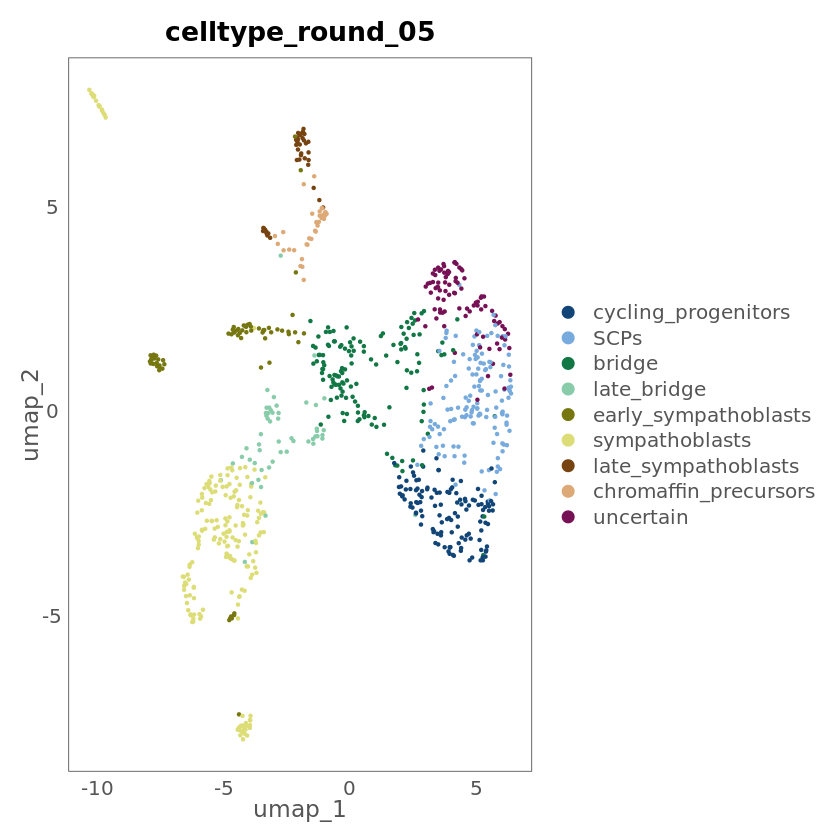

In [232]:
DimPlot(object = dat_sub, reduction = 'umap', pt.size = 0.6, group.by = "celltype_round_05",
            cols = c(tol21rainbow[c(4,6,10,12,13,15,16,18,1,2,32,24,34,28)]), shuffle = T, raster=FALSE) +
                     NoAxes() +
                     mytheme_angledYtitle

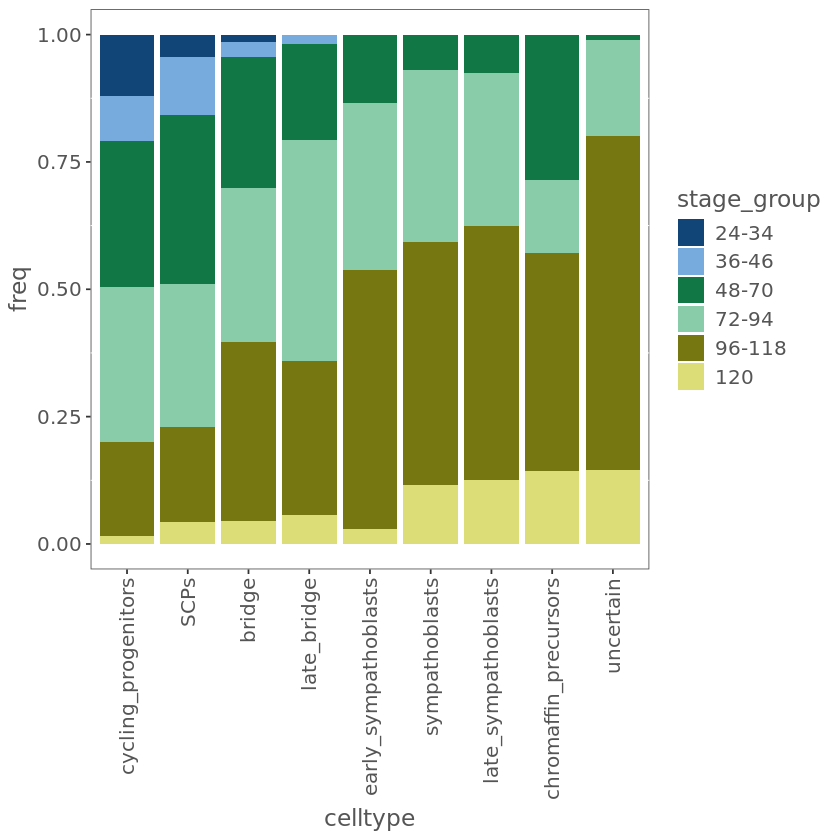

In [233]:
dat_sub$stage.group <- as.character(dat_sub$stage.group)
dat_sub$stage.group <- gsub(' ','',dat_sub$stage.group)

# widen annotation
dat_sub$stage.group_wide <- dat_sub$stage.group
dat_sub$stage.group_wide[dat_sub$stage.group_wide %in% c('48-58','60-70')] <- '48-70'
dat_sub$stage.group_wide[dat_sub$stage.group_wide %in% c('72-82','84-94')] <- '72-94'
dat_sub$stage.group_wide[dat_sub$stage.group_wide %in% c('96-106','108-118')] <- '96-118'

# get freuquency tables
clus_freqs <- as.data.frame(table(dat_sub$celltype_round_05, dat_sub$stage.group))
colnames(clus_freqs) <- c('celltype','stage_group','freq')

clus_freqs_wide <- as.data.frame(table(dat_sub$celltype_round_05, dat_sub$stage.group_wide))
colnames(clus_freqs_wide) <- c('celltype','stage_group','freq')

clus_freqs$stage_group <- factor(clus_freqs$stage_group, levels = c('14-21',
                                                                    '24-34',
                                                                    '36-46',
                                                                    '48-58',
                                                                    '60-70',
                                                                    '72-82',
                                                                    '84-94',
                                                                    '96-106',
                                                                    '108-118',
                                                                    '120')
                                )

clus_freqs_wide$stage_group <- factor(clus_freqs_wide$stage_group, levels = c('14-21',
                                                                    '24-34',
                                                                    '36-46',
                                                                    '48-70',
                                                                    '72-94',
                                                                    '96-118',
                                                                    '120')
                                )

# Stacked + percent
ggplot(clus_freqs_wide, aes(fill=stage_group, y=freq, x=celltype)) + 
    geom_bar(position="fill", stat="identity") +
    scale_fill_manual(values = tol21rainbow[c(4,6,10,12,13,15,17,3,1,24,25)]) +
    mytheme_angledX

Warning message:
“Removed 81 rows containing missing values or values outside the scale range (`geom_point()`).”


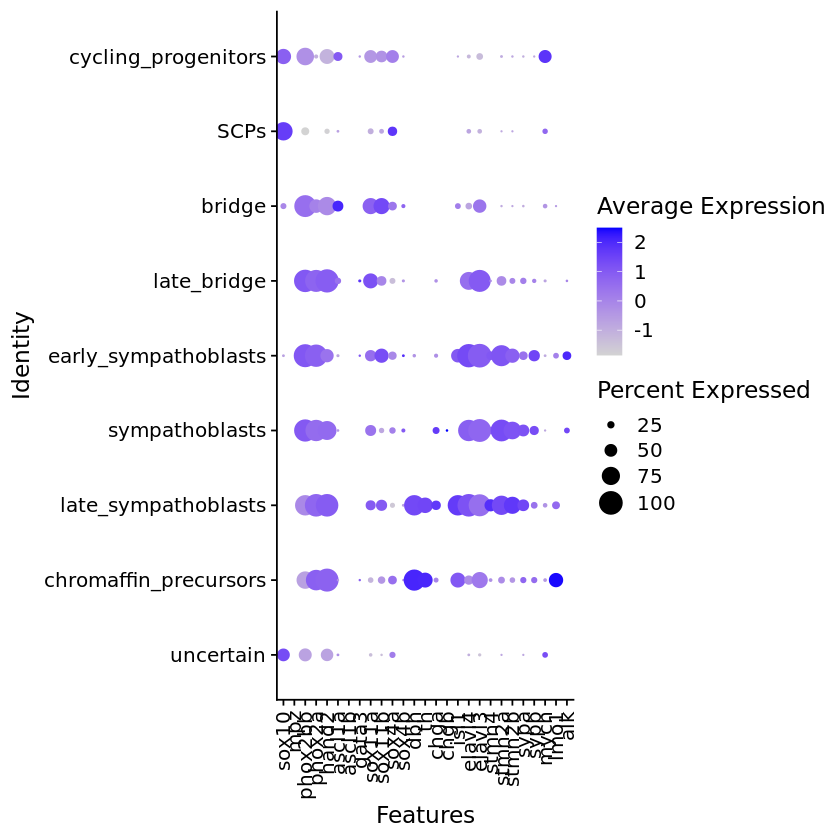

In [297]:
# individual marker genes

mods_plot <- c('sox10','mpz','phox2bb', 'phox2a','hand2','ascl1a','ascl1b','gata3','sox11a','sox11b','sox4a','sox4b','dbh','th','chga','chgb','pnmt',
               'isl1','elavl4','elavl3','stmn4','stmn2a','stmn2b','sypa','sypb','mycn','lmo1','alk')
mods_plot <- mods_plot[mods_plot %in% rownames(dat_sub)]

dat_sub$celltype_round_05 <- factor(as.character(dat_sub$celltype_round_05),
                                    levels = rev(c( 'cycling_progenitors',
                                                'SCPs',
                                                'bridge',
                                                'late_bridge',
                                                'early_sympathoblasts',
                                                'sympathoblasts',
                                                'late_sympathoblasts',
                                                'chromaffin_precursors',
                                                'uncertain'
                                             ))
                                    )

DotPlot(dat_sub, features = mods_plot, group.by = 'celltype_round_05',
        dot.min = 0.02)  +
theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1))

#### Score dev cell type modules and plot

In [236]:
# load published developmental cell type marker gene lists for human fetal adrenal medullary cells from Kildisiute et al., Kameneva et al. and Jansky et al. translated to zebrafish
markers_hum <- read.delim("fetal_adrenal_markers_dr.csv", stringsAsFactors = F, sep = ",", header = T, row.names = NULL)

# convert to list
modules_pan <- as.list(markers_hum)
modules_pan <- lapply(modules_pan, function(X) X[X != ""])
modules_pan <- lapply(modules_pan, function(X) X[X %in% rownames(dat_sub)])

# make sure correct symbols are being used in gene names
modules_pan <- lapply(modules_pan, function(x) gsub("si\\.","si:",x))
modules_pan <- lapply(modules_pan, function(x) gsub("zgc\\.","zgc:",x))
modules_pan <- lapply(modules_pan, function(x) gsub("mt\\.","mt-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("dkey\\.","dkey-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("h211\\.","h211-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("1073\\.","1073-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("1073\\.","1073-",x))
modules_pan <- lapply(modules_pan, function(x) gsub("ch73\\.","ch73-",x))
            
modules_pan <- modules_pan[lengths(modules_pan) >= 3]

Warning message:
“The `slot` argument of `GetAssayData()` is deprecated as of SeuratObject 5.0.0.
ℹ Please use the `layer` argument instead.”
Quantiles for the number of genes detected by cell: 
(Non-detected genes are shuffled at the end of the ranking. Keep it in mind when choosing the threshold for calculating the AUC).



    min      1%      5%     10%     50%    100% 
 212.00  346.66  434.45  513.30 1369.50 4962.00 


Warning message:
“useNames = NA is deprecated. Instead, specify either useNames = TRUE or useNames = FALSE.”


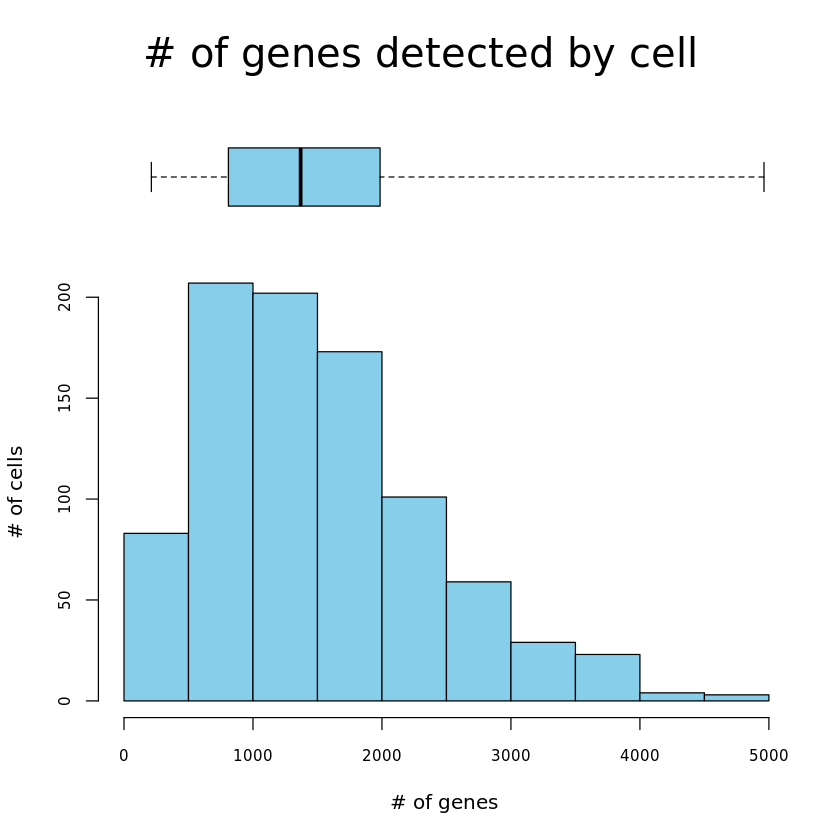

In [237]:
# Get AUC scores

enrich_list <- GeneToEnrichment(srt = dat_sub, db = modules_pan, method = 'auc')
    
save(enrich_list, file = paste0('moduleScores_AUC_human_SAdev_mods_',dat_name,'.Robj'))

In [280]:
# Reload scores, add to metadata and plot
dat_temp <- dat_sub

mod_type <- 'AUC'
load('moduleScores_AUC_human_SAdev_mods_daniocell_SAlin_sub_05.Robj')

indtumours_merge <- as.data.frame(enrich_list)


In [281]:
indtumours_merge$Barcode <- rownames(indtumours_merge)
dat_temp@meta.data$Barcode <- rownames(dat_temp@meta.data)

In [282]:
# merge scores with metadata
metadat_all <- left_join(dat_temp@meta.data, indtumours_merge, by = 'Barcode')
rownames(metadat_all) <- metadat_all$Barcode

In [283]:
# Prepare for adding scores to seurat object
dim(indtumours_merge)
dim(dat_temp@meta.data)

metadat_all <- metadat_all[order(match(rownames(metadat_all), rownames(dat_temp@meta.data))),]
table(rownames(metadat_all) == rownames(dat_temp@meta.data))

[1] 1624   19

[1] 884  35


TRUE 
 884 

In [284]:
# Add to seurat object
dat_temp@meta.data <- metadat_all

In [290]:
# Order modules
mod_names_numb <- colnames(indtumours_merge)[colnames(indtumours_merge) != 'Barcode']
mod_names_numb <- mod_names_numb[mod_names_numb %like any% c('jansky_%','kildi%')]

# Order cell types
dat_temp$celltype_round_05 <- factor(as.character(dat_temp$celltype_round_05),
                                    levels = rev(c( 'cycling_progenitors',
                                                'SCPs',
                                                'bridge',
                                                'late_bridge',
                                                'early_sympathoblasts',
                                                'sympathoblasts',
                                                'late_sympathoblasts',
                                                'chromaffin_precursors',
                                                'uncertain'
                                             ))
                                    )

colnames(dat_temp@meta.data) <- gsub('_stringent','',colnames(dat_temp@meta.data))
mod_names_numb <- gsub('_stringent','', mod_names_numb)

mod_names_numb <- c('jansky_SCPs',
                                    'jansky_Cycling_SCPs',
                                    'jansky_Late_SCPs',
                                    'jansky_Bridge',
                                    'jansky_Connecting_progens',
                                    'jansky_Cycling_neuroblasts',
                                    'jansky_Neuroblasts',
                                    'jansky_Late_neuroblasts',
                                    'jansky_Chromaffin_cells',
                                    'jansky_Late_chromaffin_cells',
                                    'kildi_SCPs',
                                    'kildi_Bridge',
                                    'kildi_Sympathoblastic',
                                    'kildi_Chromaffin'
                                    )


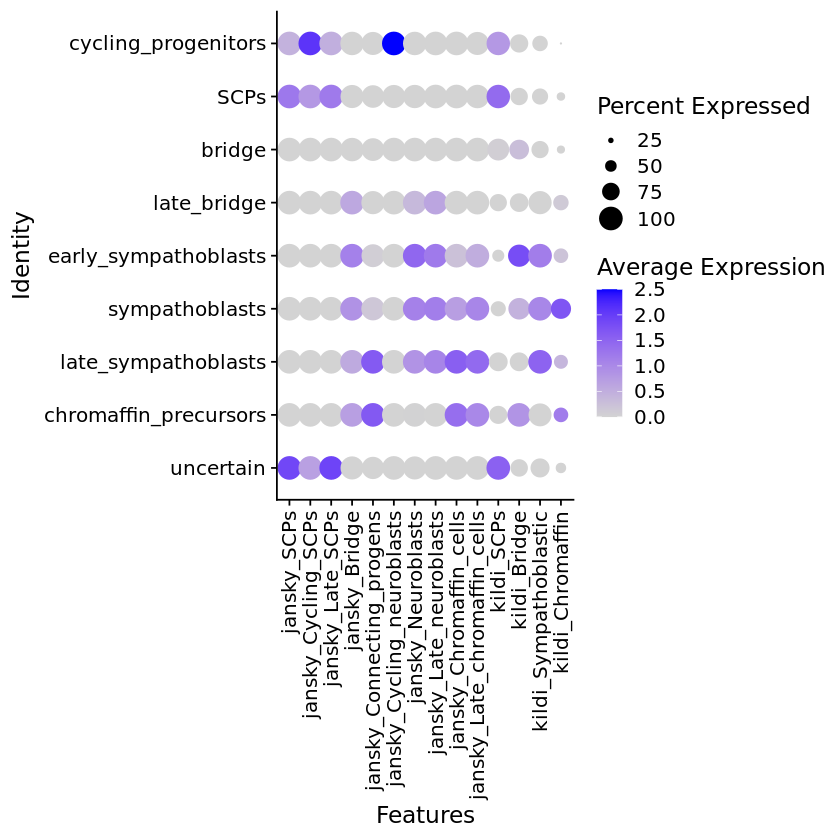

In [291]:
DotPlot(dat_temp, features = mod_names_numb, group.by = 'celltype_round_05',
            dot.min = 0.02,
            col.min = 0)  +
            theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1))

#### write out data for cellrank2

In [ ]:
dat_sub@meta.data <- dat_sub@meta.data[,c('nUMI','nGene','percent.mt',
                                         'seurat_clusters','stage.integer','stage.group','stage.group_wide',
                                          'tissue','clust','tissue.figure','tissue.name','cell.cycle.g1s',
                                          'cell.cycle.g2m','cell.cycle.class','celltype_cellrank')]

sub_dat_meta <- dat_sub@meta.data
sub_dat_counts <- GetAssayData(dat_sub, slot = 'counts')


saveRDS(dat_sub, 'cellrank_material/dev_data/Daniocell_SAlineage_seuratObj.rds')
write.csv(sub_dat_meta, file = 'cellrank_material/dev_data/Daniocell_SAlineage_metadata.csv', sep = ',', quote = F)

writeMM(sub_dat_counts,file = 'cellrank_material/dev_data/Daniocell_SAlineage_countMatrix.mtx')

write.table(rownames(dat_sub), file = 'cellrank_material/dev_data/genes.txt', quote = F)
write.table(colnames(dat_sub), file = 'cellrank_material/dev_data/cell_barcodes.txt', quote = F)